# 2026 Senate Forecast - Pray_For_The_Floor

**Pray_For_The_Floor** is the fourth model. It keeps **Model 1's backbone**: weighted polls -> national environment -> fundamentals prior -> **Bayesian precision update** -> correlated fat-tailed simulations, with every assumption in one `CONFIG`. It adds the strongest parts of the later models (a greatest-hits album, basically):

| Added | From | What it does |
|---|---|---|
| **VoteHub polls** (state, generic ballot, approval) | Ozempic / DadBod | Live data instead of Adler's spreadsheet, which stopped on Oct 14 |
| **VoteHub pollster scorecard** | DadBod | Real grades, past error and lean for each pollster, replacing the spreadsheet's rank column and the blank "Typical Error" column |
| **Kalshi as a third Bayesian input** | new | Each race's market odds become a margin with its own uncertainty (`KALSHI_SD`), combined with the prior and the polls by precision |
| **Kalshi national averages** | DadBod | RCP and VoteHub approval and VoteHub generic-ballot markets, blended with the VoteHub polls (`NAT_KALSHI_POLL_EQUIV`) |
| **Automatic Kalshi search + nominees** | DadBod | Finds every race's market by its title; candidate names come from Kalshi |
| **Random grades for ungraded pollsters, redrawn every simulation** | Ozempic / DadBod | Spreads uncertainty about unknown pollsters into the result instead of giving them the lowest grade |
| **Poll reliability dial** | DadBod | Model 1's Bayesian precision already trusts thin races less; `POLL_RELIABILITY` can add DadBod's extra discount on top |
| **Scorecard house effects** and **correlated source errors** | DadBod | Two independent on/off toggles |
| **Recency window option** | Ozempic / DadBod | Model 1's half-life (default) or the 28-day linear window |
| **Model Testing notebook** | DadBod | Checks, diagnostics, sensitivity sweep and weekly backtests, kept separate |

### What it produces
1. **P(Democrats hold at least 51 seats)**: with a Republican vice president, 51 is the number Democrats need for control
2. **The predicted number of Democratic seats**: the average over all simulated elections, counting independents who caucus with Democrats

### The model in one line
For each of the 35 races, three estimates of the margin are combined by **precision** (1 $\div$ $\text{uncertainty}^2$), so the most certain source counts most:

$$\text{margin} = \frac{\pi_F \cdot \text{prior} + \pi_P \cdot \text{polls} + \pi_K \cdot \text{Kalshi}}{\pi_F + \pi_P + \pi_K}, \qquad \pi = \frac{1}{\text{SD}^2}$$

| Symbol | What it is | Set by |
|---|---|---|
| prior | Fundamentals: 2 $\times$ partisan lean + national environment $\pm$ incumbency (Steps 5-6) | `PVI_TO_MARGIN`, `ENV_*`, `INCUMBENCY_*` |
| polls | The race's weighted polling average (Steps 2-4) | poll-weight settings |
| Kalshi | The market's win probability turned into a margin (Step 6) | - |
| $\pi_F$ | Precision of the prior: 1 $\div$ `PRIOR_SD`$^2$ (7.5 pts) | `PRIOR_SD` |
| $\pi_P$ | Precision of the polls: shrinks with fewer or noisier polls; never more than 1 $\div$ $4.5^2$ (the error shared by all of a state's polls) | `POLL_PRECISION_MULT`, `POLL_RELIABILITY`, `SYSTEMATIC_POLL_ERROR_SD` |
| $\pi_K$ | Precision of Kalshi: 1 $\div$ `KALSHI_SD`$^2$ (17 pts, deliberately small) | `KALSHI_SD` |

Each race's margin and uncertainty become a range of outcomes, and the whole election is simulated `N_SIMS` times (default 10,000) with related states moving together (Step 7). Counting seats in every simulation gives the two numbers above.

### How to use
1. Run the **install** cell once per computer.
2. Change anything in **CONFIG** (each line says what it does). The cell after it shows the formula with your numbers filled in.
3. *Run All.* Results land in `Output/` in this folder.
4. Open **`Model Testing.ipynb`** to check the run and see which settings matter most.

All margins are **Democrat (or a credible independent) minus Republican**, in percentage points. D+3 means the Democrat leads by 3.

## Glossary (plain English)

| Term | Meaning |
|---|---|
| **Margin** | Democratic % minus Republican %. D+4 = Democrat ahead by 4 points; R+4 = Republican ahead by 4. |
| **Poll** | A survey of a few hundred to a few thousand people, used to estimate how the whole state will vote. |
| **Sample size (n)** | How many people a poll interviewed. Bigger samples have less random error. |
| **LV / RV / A** | Who was polled: *likely voters*, *registered voters*, or *all adults*. LV is closest to who actually votes. |
| **Pollster grade** | VoteHub's report card (A+ to D) for how accurate a polling firm has been. Many firms have no grade. |
| **House effect** | A pollster's typical lean: how far its results usually land from the final result, and in which direction. |
| **Partisan poll** | A poll paid for by a party or campaign. These usually flatter their sponsor. |
| **Flooding** | One firm releasing many polls of the same race, which would let it dominate the average. |
| **Generic ballot** | The national question "would you vote for the Democrat or the Republican for Congress?" A read on the national mood. |
| **Net approval** | % who approve of the president minus % who disapprove. |
| **Partisan lean (PVI)** | How much more Republican or Democratic a state votes than the country, in vote-share points. Lean -15 = 15 points more Republican. |
| **Prior / fundamentals** | What we'd expect in a race before looking at its polls: partisan lean, the national mood, incumbency. |
| **Precision** | 1 $\div$ ($\text{uncertainty}^2$). A source that's twice as certain counts four times as much. This is how a Bayesian update weighs sources. |
| **Posterior** | The final estimate after combining the prior with the polls (and Kalshi). |
| **Kalshi** | A regulated prediction market. A price of 0.64 means the market gives about a 64% chance. |
| **Simulation** | One made-up election drawn from the model's ranges. Running 10,000 of them shows how often each outcome happens. |
| **Correlation** | When states tend to miss in the same direction (a polling error in Ohio usually shows up in Michigan too). |
| **Fat tails** | Big surprises (like 2016) happen more often than a bell curve suggests. The model uses a Student-t curve to allow for them. |
| **Backtest** | Re-running the model as if it were an earlier date, using only what was known then (`AS_OF_DATE`). |

## Setup: install packages
Run once per computer (safe to re-run; packages you already have are politely skipped). Installs everything this notebook and `Model Testing.ipynb` need that doesn't ship with Python. Restart the kernel if anything was newly installed.

In [1]:
%pip install --quiet numpy pandas scipy matplotlib jinja2 nbformat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import copy  # deep-copy CONFIG for sweep runs
import json  # parse API responses
import os
import re  # normalize names
import unicodedata  # strip accents from candidate names
import urllib.request  # stdlib HTTP (no extra install needed)
from pathlib import Path  # OS-independent file paths

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import Markdown, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

## CONFIG - every assumption lives here, rent free

Same layout as Model 1, grouped by model stage. **New or changed** settings are marked `NEW` / `CHANGED` in their notes. Change a value, then *Run All*. The Model Testing notebook's sweep changes one key at a time, so keys are referenced by name there.

In [3]:
# REPO_ROOT = first folder at or above the working directory that holds Data/. Since the reorg, that's the
# Senate Forecast folder (not the top of the git repo), which is exactly where Data/ and Models/ now live.
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Data").is_dir())
MODEL_DIR = REPO_ROOT / "Models" / "Pray_For_The_Floor"  # this notebook's folder

CONFIG = {
    # ---------------- Files & run settings ----------------
    "DATA_DIR": REPO_ROOT / "Data",  # shared data folder (look, don't touch)
    "OUT_DIR": MODEL_DIR / "Output",  # results written here (created if missing)
    "CACHE_DIR": MODEL_DIR / "Data_Cache",  # NEW: last good download of every source, our safety net when a website takes a nap
    "LEANS_FILE": "leans_and_regions.csv",  # partisan lean (PVI) + Census region per state
    "SCORECARD_FILE": "votehub_pollster_scorecards.csv",  # NEW: VoteHub grade, % error, house effect per pollster
    "ELECTION_DAY": "2026-11-03",
    "AS_OF_DATE": None,  # None = today. "2026-10-15" = backtest: only polls RELEASED by then, that day's Kalshi race
                         #   prices, and polls only for the national numbers (Kalshi's national averages are skipped)
    "N_SIMS": 10_000,  # simulated elections. 10,000 gives about +/-1 pt (95%) on P(51+)
    "SEED": 2026,  # same seed + same data = same numbers every run (no surprises, no sorcery)

    # ---------------- Senate map & control rules ----------------
    "SEATS_UP": {  # party currently holding each seat on the 2026 ballot (33 Class II + FL/OH specials)
        "Alabama": "R", "Alaska": "R", "Arkansas": "R", "Florida": "R", "Idaho": "R",
        "Iowa": "R", "Kansas": "R", "Kentucky": "R", "Louisiana": "R", "Maine": "R",
        "Mississippi": "R", "Montana": "R", "Nebraska": "R", "North Carolina": "R",
        "Ohio": "R", "Oklahoma": "R", "South Carolina": "R", "South Dakota": "R",
        "Tennessee": "R", "Texas": "R", "West Virginia": "R", "Wyoming": "R",
        "Colorado": "D", "Delaware": "D", "Georgia": "D", "Illinois": "D",
        "Massachusetts": "D", "Michigan": "D", "Minnesota": "D", "New Hampshire": "D",
        "New Jersey": "D", "New Mexico": "D", "Oregon": "D", "Rhode Island": "D",
        "Virginia": "D",
    },
    "HOLDOVER_D": 34,  # D + caucusing independents NOT on the ballot (47 - 13 up)
    "HOLDOVER_R": 31,  # R not on the ballot (53 - 22 up)
    "VP_PARTY": "R",  # VP breaks 50-50 ties -> with "R", Democrats need 51 (ties go to the Veep)
    "D_SEATS_FOR_CONTROL": None,  # None = derive from VP_PARTY (51 or 50). 52 = the "Fetterman switches" view
    "HOLDOVER_DEFECTION_PROB": {"Fetterman (PA)": 0.0},  # P(holdover D-caucus senator organizes with R), drawn per simulation
    "INDEPENDENT_CAUCUS_PROB_D": {"Nebraska": 0.8},  # P(independent caucuses with D if they win): Adler's 80% for Osborn
    # Incumbent status for the prior's incumbency bonus: "running", "appointed", "open". Hand-maintained; re-check before the final run.
    "INCUMBENT_STATUS": {
        "Illinois": "open", "Michigan": "open", "Minnesota": "open", "New Hampshire": "open",
        "Alabama": "open", "Iowa": "open", "Kentucky": "open", "Montana": "open",
        "North Carolina": "open", "Wyoming": "open", "Oklahoma": "open", "Texas": "open", "Louisiana": "open",
        "Florida": "appointed", "Ohio": "appointed", "South Carolina": "appointed",
    },
    "DEFAULT_INCUMBENT_STATUS": "running",  # everyone else

    # ---------------- Data cleaning ----------------
    "POLLSTER_NAME_FIXES": {},  # manual spelling fixes, e.g. {"Morning consult": "Morning Consult"}; case/punctuation
                                #   differences are merged automatically
    "MIN_SAMPLE_SIZE": 0,  # drop polls smaller than this (0 = keep all)
    "MISSING_SAMPLE_SIZE": 600,  # NEW: size assumed when VoteHub doesn't report one
    "MAX_POLL_AGE_DAYS": None,  # drop polls older than this (None = keep all; recency weighting handles age)
    "DROP_EXACT_DUPLICATES": True,  # same pollster/state/date/numbers listed twice -> keep one
    "NAT_ZERO_SAMPLE_IMPUTE": 1000,  # national polls reporting n = 0 get this size instead of zero weight

    # ---------------- Multi-version polls (same pollster/state/end date released several ways) ----------------
    # "split" (DEFAULT): keep every version, each gets 1/(# versions) so the survey counts once in total
    # "keep_all": each version counts as a separate poll | "prefer_h2h" / "prefer_full_field": keep only that version when one exists
    "POLL_VERSION_MODE": "split",
    "DROP_GENERIC_IF_CANDIDATE_VERSION": True,  # survey with both a generic (party) and a named-candidate version -> drop the generic

    # ---------------- Undecided / other voters ----------------
    # "Other" = 100 - Dem% - Rep%. Part of it is truly undecided; the rest sticks with third parties.
    # CHANGED: "full field" is now detected automatically (VoteHub lists more than two candidates)
    "OTHER_TO_UNDECIDED_H2H": 1.0,  # head-to-head: all non-D/R is undecided
    "OTHER_TO_UNDECIDED_FULL_FIELD": 0.5,  # full field: half of "other" is real third-party support
    # How undecideds break: "ignore" (raw D-R), "proportional" (like decided voters), "fixed_share" (D gets UNDECIDED_D_SHARE),
    # "against_incumbent" (challenger gets UNDECIDED_CHALLENGER_SHARE; open seats split evenly)
    "UNDECIDED_MODE": "proportional",
    "UNDECIDED_D_SHARE": 0.5,
    "UNDECIDED_CHALLENGER_SHARE": 0.55,
    "UNDECIDED_SPLIT_SD": 0.15,  # uncertainty in the share of undecideds going D; adds 2*U*SD pts of margin SD per poll

    # ---------------- Poll weights ----------------
    "RECENCY_MODE": "half_life",  # NEW: "half_life" = Model 1 (every poll counts, halving every RECENCY_HALF_LIFE_DAYS);
                                  #   "window" = Ozempic/DadBod (only the last WINDOW_DAYS, weight falling in a straight line)
    "RECENCY_HALF_LIFE_DAYS": 21,  # "half_life" mode: after ~3 weeks a poll is half as informative
    "WINDOW_DAYS": 28,  # NEW, "window" mode: polls older than this are dropped
    "WINDOW_OLDEST_WEIGHT": 0.25,  # NEW, "window" mode: weight of a poll exactly WINDOW_DAYS old (1.0 today)
    "REFERENCE_SAMPLE": 800,  # a poll this size gets sample-size weight 1.0
    "SAMPLE_SIZE_EXPONENT": 0.5,  # weight = (n/ref)^0.5 (sampling error shrinks with sqrt n). 0 = ignore size
    "SAMPLE_SIZE_CAP": 2500,  # n above this gets no extra weight; stops huge online panels dominating
    "POPULATION_WEIGHTS": {"LV": 1.0, "RV": 0.85, "A": 0.7},  # Model 1's values. The team's blackboard ratio is
                                                             #   1 : 0.9 : 0.8 (used by Ozempic and DadBod)
    "RV_MARGIN_SHIFT": -0.5,  # RV polls nudged 0.5 pt toward R
    "PARTISAN_WEIGHTS": {"Republican": 0.6, "Democrat": 0.6},  # party/campaign-sponsored polls count less
    "PARTISAN_HOUSE_EFFECTS": {"Republican": 3.0, "Democrat": 3.0},  # pts shifted AGAINST the sponsor
    "GENERIC_WEIGHT": 0.5,  # state poll asking "a Democrat or a Republican?" instead of naming candidates
    "BIGGER_FIELD_WEIGHT": 0.9,  # full-field version (3+ candidates offered); 1.0 = neutral
    # Pollster quality. CHANGED: grades come from the VoteHub scorecard instead of the spreadsheet's rank column
    "GRADE_TO_RANK": {"A+": 10, "A": 9, "B": 8, "C": 7, "D": 6, "F": 5},  # VoteHub grade -> Model 1's 5-10 scale
    "QUALITY_SCORE_MIN": 5,
    "QUALITY_SCORE_MAX": 10,
    "MIN_QUALITY_WEIGHT": 0.5,  # rank 5 counts half as much as rank 10
    "UNRATED_POLLSTERS": "random",  # NEW: pollsters VoteHub hasn't graded. "random" = in EVERY simulation each one gets
                                    #   the grade, past error and lean of a randomly drawn graded pollster (redrawn each
                                    #   simulation); "fixed" = Model 1's rule: UNRANKED_SCORE + DEFAULT_TYPICAL_ERROR, no lean
    "UNRANKED_SCORE": 5,  # "fixed" mode: rank given to ungraded pollsters (5 = lowest)
    # Typical error = pollster's mean absolute miss. CHANGED: filled from the scorecard's Percent_Error automatically
    "TYPICAL_ERROR_BY_POLLSTER": {},  # manual overrides, e.g. {"Emerson College": 3.4}
    "DEFAULT_TYPICAL_ERROR": 4.0,  # ungraded pollsters in "fixed" mode; also the reference for the accuracy weight
    "MAE_TO_SD": 1.25,  # for a normal distribution SD = 1.25 x mean absolute error
    "ACCURACY_WEIGHT_CLIP": (0.5, 2.0),  # NEW: accuracy weight kept in this range (real scorecard errors would otherwise
                                         #   let one very accurate firm count up to 10x)
    "FLOOD_EXPONENT": 0.5,  # each of a pollster's k polls in a state gets 1/k^0.5 (0 = no penalty, 1 = counts once)
    "SYSTEMATIC_POLL_ERROR_SD": 4.5,  # miss shared by all polls of a state; doesn't shrink with more polls

    # ---------------- House effects (pollster lean) ----------------
    "SCORECARD_HOUSE_EFFECTS": True,  # NEW: subtract each graded pollster's known lean (VoteHub scorecard). Skipped for
                                      #   partisan polls (they already get PARTISAN_HOUSE_EFFECTS)
    "ESTIMATE_HOUSE_EFFECTS": False,  # Model 1's data-driven estimate (residual vs state average, shrunk to 0). Off:
                                      #   with 1-2 polls per pollster it mostly chases noise
    "HOUSE_EFFECT_SHRINKAGE": 3.0,

    # ---------------- National environment ----------------
    "PRESIDENT_PARTY": "R",  # unpopular R president helps D
    "NAT_HALF_LIFE_DAYS": 30,  # approval moves slowly -> longer half-life than state polls
    "NAT_REFERENCE_SAMPLE": 1000,
    "NAT_POPULATION_WEIGHTS": {"LV": 1.0, "RV": 1.0, "Adults": 0.8},
    "NAT_PARTISAN_WEIGHT": 0.6,
    "NAT_NET_APPROVAL_SHIFT": {"LV": 0.0, "RV": 0.0, "Adults": 0.0},  # pts added to net approval by population
    "NAT_USE_QUALITY": True,  # same grade weighting for national polls (ungraded = UNRANKED_SCORE, not random)
    "ENV_SLOPE": 0.35,  # pts of Senate margin per pt of net approval
    "APPROVAL_NEUTRAL_NET": 0.0,  # net approval at which the environment is even
    "MIDTERM_PENALTY": 0.0,  # extra pts against the president's party beyond approval
    "USE_GENERIC_BALLOT": True,
    "GENERIC_BALLOT_BLEND": 0.5,  # env = blend x generic-ballot env + (1 - blend) x approval env
    "GB_LOOKBACK_DAYS": 90,  # VoteHub national coverage is thin after June, so look back further
    "GB_MIN_POLLS": 10,  # if fewer surveys than this in the window, use the N most recent
    "GB_POPULATION_PREFERENCE": ["LV", "RV", "A"],  # one survey released for several populations -> keep the most voter-like
    "GB_MARGIN_BASIS": "two_party",  # "two_party" = 100*(D-R)/(D+R); "raw" = D-R as reported
    "GB_APPLY_RV_SHIFT": True,
    "GB_HALF_LIFE_DAYS": 21,
    "GB_SHIFT": 0.0,  # pts added to the generic-ballot margin
    "NAT_KALSHI_POLL_EQUIV": 5,  # NEW: Kalshi's polling-average markets (RCP + VoteHub approval, VoteHub generic ballot)
                                 #   are blended with the VoteHub polls as if they were this many polls. 0 = ignore them
    "NAT_MIX_LOOKBACK_DAYS": 90,  # NEW: window for the typical "neither" share (approval) and D+R share (generic ballot)
                                  #   used to put Kalshi's averages on the same scale as the polls (Step 5)
    "ENV_OVERRIDE": None,  # a number (e.g. 5.0 = D+5) bypasses all of the above

    # ---------------- Fundamentals prior ----------------
    "PVI_TO_MARGIN": 2.0,  # PVI is in vote share; 1 pt share = 2 pts margin
    "ENV_ELASTICITY_DEFAULT": 1.0,  # how much each state moves with the national environment
    "ENV_ELASTICITY": {},  # per-state overrides, e.g. {"New Hampshire": 1.2}
    "INCUMBENCY_ADVANTAGE": 2.0,  # Model 1's value (the meeting notes said 3; set 3.0 to match Ozempic/DadBod)
    "APPOINTED_INCUMBENT_ADVANTAGE": 1.0,  # appointed incumbents get about half
    "STATE_PRIOR_ADJUSTMENTS": {},  # manual pts added to a state's prior, e.g. {"Texas": +2}
    "PRIOR_SD": 7.5,  # how far a race can stray from lean + environment
    "INDEPENDENT_PRIOR_SD_MULT": 1.3,  # PVI says less about races with an independent challenger -> wider prior

    # ---------------- Bayesian update ----------------
    "POLL_PRECISION_MULT": 1.0,  # >1 trusts polls more than the prior, <1 less
    "POLL_RELIABILITY": "bayesian",  # NEW: "bayesian" (DEFAULT) = Model 1: thin races are already trusted less through
                                     #   their wider poll uncertainty. A number k = ALSO multiply poll precision by
                                     #   n_eff / (n_eff + k) (DadBod's rule: half weight at k effective polls). Leans
                                     #   harder on fundamentals + Kalshi where polling is thin
    "KALSHI_SD": 17.0,  # NEW: uncertainty (pts) given to Kalshi's implied margin. Precision = 1/17^2, about 1/5 of the
                        #   prior's 1/7.5^2: the team's "fundamentals 5 : Kalshi 1". Share of the final margin: about
                        #   5-9% in polled races and 16% in unpolled ones. Smaller = trust Kalshi more.
                        #   None or 0 = Kalshi shown for comparison only
    "CORRELATED_ERRORS": True,  # NEW: True = the prior, polls and Kalshi tend to miss in the same direction (Kalshi
                                #   traders read the same polls), so each race's range is wider. Weights are unchanged.
                                #   Independent of SCORECARD_HOUSE_EFFECTS: both, either or neither can be on
    "SOURCE_ERROR_CORR": 0.3,  # NEW: how strongly they miss together when CORRELATED_ERRORS is on (0-1)

    # ---------------- Time to election ----------------
    "DAILY_DRIFT_SD": 0.25,  # extra SD per sqrt(day) left; 0 on election day
    "DRIFT_SHAPE": "sqrt",  # "sqrt" (random walk) or "linear"

    # ---------------- Error distribution ----------------
    "USE_T_DIST": True,  # fat tails: upsets more common than a normal curve implies
    "T_DF": 5,  # degrees of freedom (> 2); lower = fatter tails
    "SHARED_TAIL_SCALE": True,  # one "bad polling year" draw shared by all states

    # ---------------- Between-state correlation ----------------
    "CORR_NATIONAL": 0.45,  # every pair shares this (national polling miss / wave)
    "CORR_REGION": 0.15,  # added if same Census region
    "CORR_LEAN": 0.15,  # added x exp(-|lean_i - lean_j| / LEAN_SCALE)
    "LEAN_SCALE": 10,
    "STATE_PAIR_CORR_OVERRIDES": {},  # exact correlation for specific pairs, e.g. {("Iowa", "Kansas"): 0.8}

    # ---------------- Race ratings ----------------
    "RATING_TOSSUP": 0.60, "RATING_LEAN": 0.75, "RATING_LIKELY": 0.95,  # favorite's win probability cut-offs
}

## SOURCES - web addresses and fallback tables

Plumbing, not assumptions. The `*_FALLBACK` tables are **only a check and a backup**: Kalshi markets and nominee names are found automatically each run (Step 1). These tables are used only for a race the search misses, or where Kalshi lists a party name instead of a candidate, and Model Testing flags any disagreement.

In [4]:
SOURCES = {
    "VOTEHUB_URL": "https://api.votehub.com/polls",
    "KALSHI_URL": "https://api.elections.kalshi.com/trade-api/v2",
    "USER_AGENT": "DACSS-Team5-forecast",
    "KALSHI_SENATE_SERIES_PATTERN": r"(KX)?SENATE[A-Z]{2}S?",  # series searched for "<State> Senate winner?" events
    "KALSHI_CONTROL_SERIES": "CONTROLS",  # "Will Democrats win the U.S. Senate?"
    "KALSHI_CONTROL_FALLBACK": "CONTROLS-2026-D",
    # National polling-average markets: (signal, whose average, Kalshi series). The open event is found each run.
    "KALSHI_NATIONAL_SERIES": [("approval", "RCP", "KXTRUMPAPPROVE"), ("approval", "VoteHub", "KXTRUMPVH"),
                               ("generic_ballot", "VoteHub", "KXGENERICBALLOTVOTEHUB")],
    "KALSHI_UPDOWN_SD": 0.5,  # weekly "above X%?" markets: typical size (pts) of a week's move in a polling average
    "KALSHI_PROB_CLIP": (0.01, 0.99),  # keeps implied margins finite for 99%+ markets
    "KALSHI_HISTORY_START": "2026-06-01",  # first day of daily price history pulled for backtests

    # ---- FALLBACK / CHECK tables (checked Oct 26) ----
    "NOMINEES_FALLBACK": {  # (opposition, Republican); opposition None = highest-polling non-Republican in each poll
        "Alabama": ("Everett Wess", "Barry Moore"), "Alaska": ("Mary Peltola", "Dan Sullivan"),
        "Arkansas": ("Hallie Shoffner", "Tom Cotton"), "Colorado": ("John Hickenlooper", "Mark Baisley"),
        "Delaware": ("Chris Coons", "Michael Katz"), "Florida": ("Angie Nixon", "Ashley Moody"),
        "Georgia": ("Jon Ossoff", "Mike Collins"), "Idaho": (None, "Jim Risch"),
        "Illinois": ("Juliana Stratton", "Don Tracy"), "Iowa": ("Josh Turek", "Ashley Hinson"),
        "Kansas": ("Adam Hamilton", "Roger Marshall"), "Kentucky": ("Charles Booker", "Andy Barr"),
        "Louisiana": ("Jamie Davis", "Julia Letlow"), "Maine": ("Troy Jackson", "Susan Collins"),
        "Massachusetts": ("Ed Markey", "John Deaton"), "Michigan": ("Abdul El-Sayed", "Mike Rogers"),
        "Minnesota": ("Peggy Flanagan", "Michele Tafoya"), "Mississippi": ("Scott Colom", "Cindy Hyde-Smith"),
        "Montana": (None, "Kurt Alme"), "Nebraska": ("Dan Osborn", "Pete Ricketts"),
        "New Hampshire": ("Chris Pappas", "John Sununu"), "New Jersey": ("Cory Booker", "Justin Murphy"),
        "New Mexico": ("Ben Ray Lujan", "Larry Marker"), "North Carolina": ("Roy Cooper", "Michael Whatley"),
        "Ohio": ("Sherrod Brown", "Jon Husted"), "Oklahoma": ("N'Kiyla Thomas", "Kevin Hern"),
        "Oregon": ("Jeff Merkley", "David Brock Smith"), "Rhode Island": ("Jack Reed", "Raymond McKay"),
        "South Carolina": ("Annie Andrews", "Darline Graham"), "South Dakota": (None, "Mike Rounds"),
        "Tennessee": ("Marquita Bradshaw", "Bill Hagerty"), "Texas": ("James Talarico", "Ken Paxton"),
        "Virginia": ("Mark Warner", "Bert Mizusawa"), "West Virginia": ("Rachel Fetty Anderson", "Shelley Moore Capito"),
        "Wyoming": ("James Byrd", "Harriet Hageman"),
    },
    "KALSHI_EVENTS_FALLBACK": {  # Kalshi's tickers are inconsistent (Kentucky = SENATELA-26), hence the title search
        "Alabama": "SENATEAL-26", "Alaska": "SENATEAK-26", "Arkansas": "SENATEAR-26", "Colorado": "SENATECO-26",
        "Delaware": "SENATEDE-26", "Florida": "SENATEFLS-26", "Georgia": "SENATEGA-26", "Idaho": "SENATEID-26",
        "Illinois": "SENATEIL-26", "Iowa": "SENATEIA-26", "Kansas": "SENATEKS-26", "Kentucky": "SENATELA-26",
        "Louisiana": "KXSENATELA-26NOV", "Maine": "SENATEME-26", "Massachusetts": "SENATEMA-26",
        "Michigan": "SENATEMI-26", "Minnesota": "SENATEMN-26", "Mississippi": "SENATEMS-26", "Montana": "SENATEMT-26",
        "Nebraska": "SENATENE-26", "New Hampshire": "SENATENH-26", "New Jersey": "SENATENJ-26",
        "New Mexico": "SENATENM-26", "North Carolina": "SENATENC-26", "Ohio": "SENATEOHS-26",
        "Oklahoma": "SENATEOK-26", "Oregon": "SENATEOR-26", "Rhode Island": "SENATERI-26",
        "South Carolina": "SENATESC-26", "South Dakota": "SENATESD-26", "Tennessee": "SENATETN-26",
        "Texas": "SENATETX-26", "Virginia": "SENATEVA-26", "West Virginia": "SENATEWV-26", "Wyoming": "SENATEWY-26",
    },
}

### Shared settings from `run_all.py`
When `run_all.py` lines every model up for a side-by-side showdown, it makes them all play by the same rules: the same date (today's system date) and the same number of simulations (10,000), smuggled in through two environment variables that this cell reads. **When you run this notebook yourself, nothing is set and your CONFIG values call the shots.**

In [5]:
if os.environ.get("FORECAST_AS_OF"):  # only run_all.py ever sets this
    CONFIG["AS_OF_DATE"] = os.environ["FORECAST_AS_OF"]
if os.environ.get("FORECAST_N_SIMS"):
    CONFIG["N_SIMS"] = int(os.environ["FORECAST_N_SIMS"])
if os.environ.get("FORECAST_AS_OF") or os.environ.get("FORECAST_N_SIMS"):
    print(f"run_all.py overrides: AS_OF_DATE = {CONFIG['AS_OF_DATE']}, N_SIMS = {CONFIG['N_SIMS']:,}")

run_all.py overrides: AS_OF_DATE = 2026-11-02, N_SIMS = 10,000


### Checks and the formula with your current settings
`validate_config` catches impossible settings before they can quietly cook up nonsense. The formula below is rewritten with the numbers from CONFIG, so anyone can see exactly what this run does.

In [6]:
def validate_config(cfg):
    """Catch impossible settings before they produce silent nonsense."""
    assert cfg["T_DF"] > 2, "T_DF must be > 2 (t variance is undefined otherwise)"
    assert cfg["CORR_NATIONAL"] + cfg["CORR_REGION"] + cfg["CORR_LEAN"] < 1, "correlations must leave room for state noise"
    assert 0 <= cfg["GENERIC_BALLOT_BLEND"] <= 1, "GENERIC_BALLOT_BLEND must be in [0, 1]"
    assert cfg["POLL_VERSION_MODE"] in {"split", "keep_all", "prefer_h2h", "prefer_full_field"}
    assert cfg["UNDECIDED_MODE"] in {"ignore", "proportional", "fixed_share", "against_incumbent"}
    assert cfg["DRIFT_SHAPE"] in {"sqrt", "linear"}
    assert cfg["RECENCY_MODE"] in {"half_life", "window"}, "RECENCY_MODE: 'half_life' or 'window'"
    assert cfg["UNRATED_POLLSTERS"] in {"random", "fixed"}, "UNRATED_POLLSTERS: 'random' or 'fixed'"
    assert cfg["POLL_RELIABILITY"] == "bayesian" or float(cfg["POLL_RELIABILITY"]) >= 0, "POLL_RELIABILITY: 'bayesian' or a number >= 0"
    assert cfg["KALSHI_SD"] in (None, 0) or cfg["KALSHI_SD"] > 0, "KALSHI_SD: a positive number, or None/0 to switch Kalshi off"
    assert 0 <= cfg["SOURCE_ERROR_CORR"] < 1 and cfg["NAT_KALSHI_POLL_EQUIV"] >= 0
    assert 0 <= cfg["WINDOW_OLDEST_WEIGHT"] <= 1 and cfg["WINDOW_DAYS"] > 0
    assert cfg["RATING_TOSSUP"] <= cfg["RATING_LEAN"] <= cfg["RATING_LIKELY"] <= 1
    assert cfg["HOLDOVER_D"] + cfg["HOLDOVER_R"] + len(cfg["SEATS_UP"]) == 100, "seat counts must total 100"


def control_threshold(cfg):
    """Seats Democrats need for control (50 if a D VP breaks ties, 51 if R)."""
    if cfg["D_SEATS_FOR_CONTROL"] is not None:
        return cfg["D_SEATS_FOR_CONTROL"]
    return 50 if cfg["VP_PARTY"] == "D" else 51


def kalshi_on(cfg):
    return bool(cfg["KALSHI_SD"])


def render_formula(cfg):
    c = cfg
    ks = c["KALSHI_SD"]
    rel = c["POLL_RELIABILITY"]
    rec = (f"half-life {c['RECENCY_HALF_LIFE_DAYS']} days (all polls)" if c["RECENCY_MODE"] == "half_life"
           else f"last {c['WINDOW_DAYS']} days, weight 1.0 -> {c['WINDOW_OLDEST_WEIGHT']}")
    lines = [
        "**margin** = (pi_F x prior + pi_P x polls + pi_K x Kalshi) / (pi_F + pi_P + pi_K)",
        f"- pi_F = 1 / {c['PRIOR_SD']:g}^2 (independent-led races: 1 / ({c['PRIOR_SD']:g}x{c['INDEPENDENT_PRIOR_SD_MULT']:g})^2)",
        f"- pi_P = {c['POLL_PRECISION_MULT']:g} / poll SD^2, poll SD = sqrt(single-poll SD^2 / n_eff + {c['SYSTEMATIC_POLL_ERROR_SD']:g}^2 + undecided SD^2)"
        + ("" if rel == "bayesian" else f", x n_eff / (n_eff + {rel}) (extra reliability discount)"),
        f"- pi_K = 1 / {ks:g}^2 (Kalshi margin = Phi^-1(P_Kalshi) x the race's prior+polls SD)" if kalshi_on(c)
        else "- pi_K = 0 (Kalshi shown for comparison only)",
        f"- prior = {c['PVI_TO_MARGIN']:g} x partisan lean + {c['ENV_ELASTICITY_DEFAULT']:g} x national environment +/- incumbency "
        f"({c['INCUMBENCY_ADVANTAGE']:g} pts; appointed {c['APPOINTED_INCUMBENT_ADVANTAGE']:g})",
        f"- national environment = {c['GENERIC_BALLOT_BLEND']:g} x generic ballot + {1 - c['GENERIC_BALLOT_BLEND']:g} x "
        f"{c['ENV_SLOPE']:g} x -(net approval); each = VoteHub polls + Kalshi averages counted as {c['NAT_KALSHI_POLL_EQUIV']:g} polls",
        f"- polls: recency {rec}; LV:RV:A = " + ":".join(f"{v:g}" for v in c["POPULATION_WEIGHTS"].values())
        + f"; sample size (n/{c['REFERENCE_SAMPLE']})^{c['SAMPLE_SIZE_EXPONENT']} capped at {c['SAMPLE_SIZE_CAP']:,}"
        + f"; flooding 1/k^{c['FLOOD_EXPONENT']}; partisan: weight {c['PARTISAN_WEIGHTS']['Republican']:g}, shift "
        f"{c['PARTISAN_HOUSE_EFFECTS']['Republican']:g} pts; scorecard house effects {'on' if c['SCORECARD_HOUSE_EFFECTS'] else 'off'}"
        f"; ungraded pollsters {c['UNRATED_POLLSTERS']}",
        f"- uncertainty: source errors {'correlated (rho = ' + str(c['SOURCE_ERROR_CORR']) + ')' if c['CORRELATED_ERRORS'] else 'independent'}"
        f"; Student-t df {c['T_DF']}; correlation national {c['CORR_NATIONAL']} + region {c['CORR_REGION']} + lean {c['CORR_LEAN']}"
        f"; {c['N_SIMS']:,} simulations" + (f"; backtest as of {c['AS_OF_DATE']}" if c["AS_OF_DATE"] else ""),
    ]
    display(Markdown("\n".join(lines)))


validate_config(CONFIG)
for k in ("OUT_DIR", "CACHE_DIR"):
    CONFIG[k].mkdir(parents=True, exist_ok=True)
print(f"{len(CONFIG['SEATS_UP'])} races | D needs {control_threshold(CONFIG)} seats "
      f"({control_threshold(CONFIG) - CONFIG['HOLDOVER_D']} wins) | data root: {REPO_ROOT}")
render_formula(CONFIG)

35 races | D needs 51 seats (17 wins) | data root: C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast\Senate Forecast


**margin** = (pi_F x prior + pi_P x polls + pi_K x Kalshi) / (pi_F + pi_P + pi_K)
- pi_F = 1 / 7.5^2 (independent-led races: 1 / (7.5x1.3)^2)
- pi_P = 1 / poll SD^2, poll SD = sqrt(single-poll SD^2 / n_eff + 4.5^2 + undecided SD^2)
- pi_K = 1 / 17^2 (Kalshi margin = Phi^-1(P_Kalshi) x the race's prior+polls SD)
- prior = 2 x partisan lean + 1 x national environment +/- incumbency (2 pts; appointed 1)
- national environment = 0.5 x generic ballot + 0.5 x 0.35 x -(net approval); each = VoteHub polls + Kalshi averages counted as 5 polls
- polls: recency half-life 21 days (all polls); LV:RV:A = 1:0.85:0.7; sample size (n/800)^0.5 capped at 2,500; flooding 1/k^0.5; partisan: weight 0.6, shift 3 pts; scorecard house effects on; ungraded pollsters random
- uncertainty: source errors correlated (rho = 0.3); Student-t df 5; correlation national 0.45 + region 0.15 + lean 0.15; 10,000 simulations; backtest as of 2026-11-02

## Step 1: Load the raw data

**In plain English:** fetch the freshest polls and market prices. If a website is down, fall back on the last copy saved in `Data_Cache/` and say so. Files are read once here; everything that depends on `CONFIG` happens inside `run_model()`, so Model Testing can re-run it with different settings without downloading again.

| Source | What | Saved copy |
|---|---|---|
| VoteHub `us-senator` | Every 2026 Senate general-election poll (state, pollster, dates, sample, results) | `votehub_senate_cache.csv` |
| VoteHub `generic-ballot` | National "which party for Congress?" polls | `votehub_generic_ballot_cache.csv` |
| VoteHub `approval` (Donald Trump) | Presidential approval polls | `votehub_approval_cache.csv` |
| Kalshi Senate markets | Every race's market, **found automatically** by title ("Maine Senate winner?"), with candidate names and prices, plus the Senate-control market | `kalshi_races_cache.csv` |
| Kalshi national markets | Today's polling-average markets: RCP approval, VoteHub approval, VoteHub generic ballot | `kalshi_national_cache.csv` |
| Kalshi price history | Daily closing prices, pulled only for backtests (`AS_OF_DATE`) | `kalshi_history_cache.csv` |
| `Data/` files | Partisan lean + region per state, VoteHub pollster scorecards | - |

**Why search Kalshi by title?** Kalshi's codes aren't consistent: Kentucky's race is filed under `SENATELA-26` (LA = Louisiana!) and Louisiana's under `KXSENATELA-26NOV`. Searching by title finds the right market regardless. The fallback table is used only for races the search misses.

**Matching poll candidates:** VoteHub lists candidates by name, not party, so each poll is matched to the nominees (from Kalshi's market names) by surname. The opposition is the highest-polling non-Republican nominee (the "credible independent" rule, e.g. Osborn in Nebraska). Polls listing "Democrat" / "Republican" instead of names are kept as **generic** polls. Polls missing a nominee (old hypothetical match-ups) are dropped.

In [7]:
SOURCE_STATUS = {}  # source -> "live" or "cache (...)"; read by Model Testing and run_all.py


def http_json(url, timeout=20):
    req = urllib.request.Request(url, headers={"User-Agent": SOURCES["USER_AGENT"], "Accept": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as r:  # 20 s timeout so a dead API can't hang the notebook
        return json.load(r)


def with_cache(name, fetch, parse_dates):
    """Run fetch(); save to the cache on success, read the cache on failure."""
    path = CONFIG["CACHE_DIR"] / name
    try:
        df = fetch()
        if df is None or df.empty:
            raise ValueError("empty result")
        df.to_csv(path, index=False)
        SOURCE_STATUS[name] = "live"
        print(f"{name}: fetched {len(df)} rows live")
    except Exception as e:  # network down, API changed, ...
        if not path.exists():
            raise RuntimeError(f"{name}: API failed ({type(e).__name__}: {e}) and there is no saved copy") from e
        df = pd.read_csv(path)
        SOURCE_STATUS[name] = f"cache ({type(e).__name__})"
        print(f"{name}: API unavailable ({type(e).__name__}); using saved copy with {len(df)} rows")
    for c in parse_dates:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], utc=True).dt.tz_localize(None).dt.normalize()
    return df


# ---------------- VoteHub ----------------
def fetch_senate():
    rows = []
    for p in http_json(f"{SOURCES['VOTEHUB_URL']}?poll_type=us-senator"):
        subj = str(p.get("subject") or "")
        if not subj.startswith("2026 ") or subj.endswith((" Democratic", " Republican")):
            continue  # 2026 general-election polls only (drop primaries)
        state = subj[5:]
        if state not in CONFIG["SEATS_UP"]:
            continue
        rows.append({"id": p.get("id"), "end_date": p.get("end_date"), "created_at": p.get("created_at"),
                     "state": state, "pollster": p.get("pollster"), "sample_size": p.get("sample_size"),
                     "population": (p.get("population") or "").lower(), "partisan": p.get("partisan") or "",
                     "internal": bool(p.get("internal")),
                     "answers": "|".join(f"{a['choice']}={a['pct']}" for a in p.get("answers", []))})
    return pd.DataFrame(rows)


NAT_COLS = {"generic-ballot": ["Dem", "Rep"], "approval": ["Approve", "Disapprove"]}


def fetch_national(poll_type, keys, extra=""):
    rows = []
    for p in http_json(f"{SOURCES['VOTEHUB_URL']}?poll_type={poll_type}{extra}"):
        ans = {a["choice"].strip().lower(): a["pct"] for a in p.get("answers", [])}
        vals = [next((v for k, v in ans.items() if k.startswith(key)), None) for key in keys]
        if None in vals:
            continue
        rows.append({"Date": p.get("end_date"), "Released": p.get("created_at"), "Pollster": p.get("pollster"),
                     **dict(zip(NAT_COLS[poll_type], vals)), "SampleSize": p.get("sample_size"),
                     "Population": (p.get("population") or "").upper(),
                     "Partisan": bool(p.get("partisan") or p.get("internal"))})
    return pd.DataFrame(rows)


# ---------------- Kalshi ----------------
def kalshi_mid(m):
    """Mid price (0-1) of a Kalshi market; handles *_dollars (new) and cents (old) fields."""
    def f(k):
        v = m.get(k + "_dollars")
        if v not in (None, ""):
            return float(v)
        v = m.get(k)
        return None if v in (None, "") else float(v) / 100
    bid, ask, last = f("yes_bid"), f("yes_ask"), f("last_price")
    if bid and ask and ask >= bid:
        return (bid + ask) / 2
    return last


def is_live_market(m):
    return str(m.get("status", "active")).lower() in ("active", "open", "initialized", "unopened")


def fetch_kalshi_races():
    """Find each 2026 Senate race on Kalshi by its TITLE, not its ticker. Fallback table only for races the search misses."""
    today = pd.Timestamp.today().strftime("%Y-%m-%d")
    K = SOURCES["KALSHI_URL"]
    series = [s["ticker"] for s in http_json(f"{K}/series?category=Elections&tags=Senate").get("series", [])
              if re.fullmatch(SOURCES["KALSHI_SENATE_SERIES_PATTERN"], s["ticker"])]
    found = {}
    for ser in series:
        try:
            events = http_json(f"{K}/events?series_ticker={ser}&status=open&with_nested_markets=true").get("events", [])
        except Exception:
            continue
        for ev in events:
            m = re.fullmatch(r"(.+?) Senate winner\?", str(ev.get("title") or "").strip())
            is_2026 = "2026" in str(ev.get("sub_title") or "") or "-26" in ev.get("event_ticker", "")
            if not m or not is_2026 or m.group(1).strip() not in CONFIG["SEATS_UP"]:
                continue
            mk = [x for x in ev.get("markets", []) if is_live_market(x)]
            if not any(x["ticker"].endswith("-R") for x in mk):
                continue
            vol = sum(float(x.get("volume_fp") or x.get("volume") or 0) for x in mk)
            st = m.group(1).strip()
            if st not in found or vol > found[st][0]:  # two events for one race -> keep the busier one
                found[st] = (vol, ev, mk, "search")
    for st, ev_t in SOURCES["KALSHI_EVENTS_FALLBACK"].items():  # races the search missed
        if st not in found:
            try:
                j = http_json(f"{K}/events/{ev_t}?with_nested_markets=true")
                ev = j.get("event", {})
                mk = [x for x in (j.get("markets") or ev.get("markets", [])) if is_live_market(x)]
                found[st] = (0, {**ev, "event_ticker": ev_t}, mk, "fallback table")
            except Exception:
                pass
    rows = []
    for st, (_, ev, mk, how) in found.items():
        for x in mk:
            rows.append({"State": st, "event_ticker": ev.get("event_ticker"), "event_title": ev.get("title"),
                         "market_ticker": x["ticker"], "side": "R" if x["ticker"].endswith("-R") else "OPP",
                         "name": x.get("yes_sub_title") or x.get("subtitle"), "p_mid": kalshi_mid(x),
                         "found_by": how, "fetched": today})
    ctrl = None  # Senate-control market
    try:
        for ev in http_json(f"{K}/events?series_ticker={SOURCES['KALSHI_CONTROL_SERIES']}&status=open"
                            f"&with_nested_markets=true").get("events", []):
            if "2026" in ev.get("event_ticker", "") or "2026" in str(ev.get("sub_title") or ""):
                ctrl = next((x for x in ev.get("markets", []) if "democ" in str(x.get("yes_sub_title", "")).lower()), ctrl)
    except Exception:
        pass
    if ctrl is None:
        ctrl = http_json(f"{K}/markets/{SOURCES['KALSHI_CONTROL_FALLBACK']}")["market"]
    rows.append({"State": "CONTROL", "event_ticker": ctrl.get("event_ticker"), "event_title": ctrl.get("title"),
                 "market_ticker": ctrl["ticker"], "side": "D", "name": ctrl.get("yes_sub_title"), "p_mid": kalshi_mid(ctrl),
                 "found_by": "search", "fetched": today})
    return pd.DataFrame(rows)


def fetch_kalshi_national():
    """Today's polling-average markets. In each series, the open event closing soonest = the current reading."""
    today = pd.Timestamp.today().strftime("%Y-%m-%d")
    rows = []
    for signal, source, ser in SOURCES["KALSHI_NATIONAL_SERIES"]:
        try:
            events = http_json(f"{SOURCES['KALSHI_URL']}/events?series_ticker={ser}&status=open&with_nested_markets=true").get("events", [])
        except Exception:
            continue
        events = [e for e in events if e.get("markets")]
        if not events:
            continue
        ev = min(events, key=lambda e: min(str(m.get("close_time") or "9") for m in e["markets"]))
        for m in ev["markets"]:
            rows.append({"signal": signal, "source": source, "series_ticker": ser, "event_ticker": ev.get("event_ticker"),
                         "market_ticker": m["ticker"], "strike_type": m.get("strike_type"), "floor_strike": m.get("floor_strike"),
                         "cap_strike": m.get("cap_strike"), "p_mid": kalshi_mid(m), "fetched": today})
    return pd.DataFrame(rows)


def candle_value(c, side):
    d = c.get(side) or {}
    if d.get("close_dollars") not in (None, ""):
        return float(d["close_dollars"])
    return None if d.get("close") in (None, "") else float(d["close"]) / 100


def fetch_kalshi_history():
    """Daily closes of every race's Republican market + the control market (one request per market)."""
    start = int(pd.Timestamp(SOURCES["KALSHI_HISTORY_START"], tz="UTC").timestamp())
    end = int(pd.Timestamp.now(tz="UTC").timestamp())
    k = DATA["kalshi_races"]
    rows = []
    for m in k.loc[k["side"].isin(["R", "D"]), "market_ticker"]:
        j = http_json(f"{SOURCES['KALSHI_URL']}/series/{m.split('-')[0]}/markets/{m}/candlesticks"
                      f"?start_ts={start}&end_ts={end}&period_interval=1440")
        for c in j.get("candlesticks", []):
            rows.append({"market_ticker": m, "end_period_ts": c["end_period_ts"], "yes_bid": candle_value(c, "yes_bid"),
                         "yes_ask": candle_value(c, "yes_ask"), "last": candle_value(c, "price")})
    return pd.DataFrame(rows)


def load_static(cfg):
    d = cfg["DATA_DIR"]
    leans = pd.read_csv(d / cfg["LEANS_FILE"], encoding="utf-8-sig")  # utf-8-sig strips the byte-order mark
    leans = leans[leans["State"] != "Source"].copy()  # drop the citation row
    leans["State"] = leans["State"].str.strip()
    leans["PartisanLean"] = pd.to_numeric(leans["PartisanLean"])
    cards = pd.read_csv(d / cfg["SCORECARD_FILE"])
    he = cards["House_Effect"].astype(str).str.strip()
    cards["house_effect_d"] = he.str[2:].astype(float) * np.where(he.str.startswith("D"), 1.0, -1.0)  # + = leans D
    return {"leans": leans.set_index("State"), "scorecards": cards}


DATA = {
    **load_static(CONFIG),
    "senate": with_cache("votehub_senate_cache.csv", fetch_senate, ["end_date", "created_at"]),
    "generic": with_cache("votehub_generic_ballot_cache.csv", lambda: fetch_national("generic-ballot", ["dem", "rep"]),
                          ["Date", "Released"]),
    "approval": with_cache("votehub_approval_cache.csv",
                           lambda: fetch_national("approval", ["approve", "disapprove"], "&subject=Donald%20Trump"),
                           ["Date", "Released"]),
    "kalshi_races": with_cache("kalshi_races_cache.csv", fetch_kalshi_races, []),
    "kalshi_national": with_cache("kalshi_national_cache.csv", fetch_kalshi_national, []),
}
if "found_by" not in DATA["kalshi_races"].columns:  # saved copies written before this column existed
    DATA["kalshi_races"]["found_by"] = "saved copy"

votehub_senate_cache.csv: fetched 520 rows live


votehub_generic_ballot_cache.csv: fetched 548 rows live


votehub_approval_cache.csv: fetched 1026 rows live


kalshi_races_cache.csv: fetched 75 rows live


kalshi_national_cache.csv: fetched 11 rows live


### Nominees, Kalshi check, and the poll table
Nominees come from Kalshi's candidate names (the fallback table only where Kalshi lists a party). Each VoteHub poll is then turned into one row with Model 1's columns: `Dem%` (the opposition nominee, incl. a credible independent), `Rep%`, `LVorRV`, `Partisan`, `Generic`, `Bigger_Field` (3+ candidates offered), plus the pollster's VoteHub grade, past error and lean.

In [8]:
def surname(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode().lower()
    s = re.sub(r"[^a-z\- ]", "", s).strip()
    return s.split()[-1] if s else ""


def build_nominees(data):
    """{state: (republican, [opposition])} from Kalshi's market names; the fallback table only where Kalshi lists a party."""
    k = data["kalshi_races"]
    generic = lambda n: (not isinstance(n, str)) or "party" in n.lower()
    out, check = {}, []
    for st in CONFIG["SEATS_UP"]:
        g = k[k["State"] == st]
        hand_opp, hand_rep = SOURCES["NOMINEES_FALLBACK"][st]
        rep_k = [n for n in g.loc[g["side"] == "R", "name"] if not generic(n)]
        opp_k = [n for n in g.loc[g["side"] == "OPP", "name"] if not generic(n)]
        rep = rep_k[0] if rep_k else hand_rep
        opp = opp_k if opp_k else ([hand_opp] if hand_opp else [])
        source = "Kalshi" if rep_k and opp_k else ("fallback table" if g.empty else "Kalshi + fallback table (Kalshi lists parties)")
        agree = surname(rep) == surname(hand_rep) and (hand_opp is None or surname(hand_opp) in {surname(n) for n in opp})
        out[st] = (rep, opp)
        check.append({"State": st, "republican": rep, "opposition": ", ".join(opp) or "(top non-R in each poll)",
                      "source": source, "matches_fallback_table": agree})
    return out, pd.DataFrame(check).set_index("State")


NOMINEES, NOMINEE_CHECK = build_nominees(DATA)
_kr = DATA["kalshi_races"]
KALSHI_CHECK = pd.DataFrame({
    "found_event": _kr[_kr["side"] == "R"].set_index("State")["event_ticker"].reindex(sorted(CONFIG["SEATS_UP"])),
    "found_by": _kr[_kr["side"] == "R"].set_index("State")["found_by"].reindex(sorted(CONFIG["SEATS_UP"])),
    "fallback_table": pd.Series(SOURCES["KALSHI_EVENTS_FALLBACK"]),
})
KALSHI_CHECK["matches_fallback_table"] = KALSHI_CHECK["found_event"] == KALSHI_CHECK["fallback_table"]


def parse_answers(s):
    out = []
    for part in str(s).split("|"):
        if "=" in part:
            name, pct = part.rsplit("=", 1)
            out.append((name.strip(), float(pct)))
    return out


def party_answer(name):
    """'D' / 'R' if a poll answer is a party (generic ballot), else None."""
    n = name.lower()
    if re.search(r"\bdemocrat", n) and not re.search(r"\brepublican", n):
        return "D"
    if re.search(r"\brepublican", n) and not re.search(r"\bdemocrat", n):
        return "R"
    return None


def match_poll(row):
    """(dem_pct, rep_pct, n_candidates, generic) or None. 'dem' = the opposition (incl. a credible independent)."""
    ans = parse_answers(row["answers"])
    parties = {party_answer(n): p for n, p in ans if party_answer(n)}
    if "D" in parties and "R" in parties and len(parties) == len(ans):  # every answer is a party -> generic poll
        return parties["D"], parties["R"], len(ans), True
    rep_name, opp_names = NOMINEES[row["state"]]
    rep = next((p for n, p in ans if surname(n) == surname(rep_name)), None)
    if rep is None:
        return None
    others = [(n, p) for n, p in ans if surname(n) != surname(rep_name)]
    if opp_names:
        keys = {surname(n) for n in opp_names}
        opp = max((p for n, p in others if surname(n) in keys), default=None)  # highest-polling opposition nominee
    else:
        opp = max((p for _, p in others), default=None)
    return None if opp is None else (opp, rep, len(ans), False)


def scorecard_lookup(cards):
    """pollster name -> (VoteHub grade, % error, house effect); unknown pollsters -> (None, nan, nan)."""
    key = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
    lut = {}
    for _, r in cards.iterrows():
        names = [r["Scorecard_Name"]] + (str(r["Aliases"]).split("|") if pd.notna(r["Aliases"]) else [])
        for n in names:
            lut[key(n)] = (r["Grade"], float(r["Percent_Error"]), float(r["house_effect_d"]))
    return lambda p: lut.get(key(p), (None, np.nan, np.nan))


def build_poll_table(data):
    """VoteHub state polls -> one row per poll version, in Model 1's column names."""
    raw = data["senate"]
    m = raw.apply(match_poll, axis=1) if len(raw) else pd.Series(dtype=object)
    keep = m.notna().to_numpy(dtype=bool)
    p, m = raw[keep].copy(), m[keep]
    party = p["partisan"].fillna("").astype(str).str.upper()
    look = p["pollster"].map(scorecard_lookup(data["scorecards"]))
    out = pd.DataFrame({
        "Date": p["end_date"], "Released": p["created_at"] if "created_at" in p else pd.NaT,
        "State": p["state"], "Pollster": p["pollster"].astype(str),
        "Dem%": [x[0] for x in m], "Rep%": [x[1] for x in m], "n_cands": [x[2] for x in m], "Generic": [x[3] for x in m],
        "SampleSize": pd.to_numeric(p["sample_size"], errors="coerce"),
        "LVorRV": p["population"].fillna("").astype(str).str.upper().replace({"ADULTS": "A", "V": "RV"}),
        "Partisan": np.where(party.str.startswith("REP"), "Republican", np.where(party.str.startswith("DEM"), "Democrat", None)),
        "Grade": [x[0] for x in look], "Scorecard Error": [x[1] for x in look], "Scorecard Lean": [x[2] for x in look],
    })
    out["Partisan"] = out["Partisan"].astype("string")
    out["Bigger_Field"] = out["n_cands"] > 2
    out["Unrated"] = out["Grade"].isna()
    return out.reset_index(drop=True), int((~keep).sum())


DATA["polls"], N_UNMATCHED = build_poll_table(DATA)
print(f"Kalshi: {KALSHI_CHECK['found_event'].notna().sum()}/35 races found "
      f"({(KALSHI_CHECK['found_by'] == 'search').sum()} by title search); "
      f"nominees from Kalshi for {(NOMINEE_CHECK['source'] == 'Kalshi').sum()}/35 races")
print(f"VoteHub state polls: {len(DATA['senate'])} general-election rows -> {len(DATA['polls'])} with the nominees "
      f"({N_UNMATCHED} dropped: old hypothetical match-ups); {DATA['polls']['Unrated'].sum()} from ungraded pollsters")

Kalshi: 35/35 races found (24 by title search); nominees from Kalshi for 34/35 races
VoteHub state polls: 520 general-election rows -> 408 with the nominees (112 dropped: old hypothetical match-ups); 237 from ungraded pollsters


## Step 2: Clean the polls

- **Pollster names:** fixes from `POLLSTER_NAME_FIXES`, then spellings that differ only by case/punctuation are merged (otherwise the flooding penalty would treat "Morning consult" and "Morning Consult" as two firms).
- **Duplicates** (`DROP_EXACT_DUPLICATES`): identical rows listed twice are dropped.
- **As-of filter** (backtests): only polls **released** by `AS_OF_DATE` (VoteHub's `created_at`), so nothing published later leaks in.
- **Age filter:** `MAX_POLL_AGE_DAYS`, or the `WINDOW_DAYS` window when `RECENCY_MODE = "window"`.
- **Versions** (`POLL_VERSION_MODE`): one survey released several ways (e.g. likely and registered voters, or head-to-head and full field) counts once in total by default. A generic version is dropped when a named-candidate version of the same survey exists.

In [9]:
def normalize_pollsters(names, fixes):
    """Apply manual fixes, then merge spellings that differ only by case/punctuation."""
    s = names.astype(str).str.strip().replace(fixes)
    key = s.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    canonical = s.groupby(key).agg(lambda x: x.value_counts().index[0])  # most common spelling per key
    return key.map(canonical)


def resolve_today(cfg):
    """Model 'as of' date: AS_OF_DATE if set, otherwise today."""
    return pd.Timestamp(cfg["AS_OF_DATE"]) if cfg["AS_OF_DATE"] else pd.Timestamp.today().normalize()


def is_backtest(today):
    return today < pd.Timestamp.today().normalize()


def clean_polls(raw, cfg, today, verbose=False):
    p = raw.copy()
    if p.empty:
        return p
    p["Pollster"] = normalize_pollsters(p["Pollster"], cfg["POLLSTER_NAME_FIXES"])
    p["SampleSize"] = p["SampleSize"].fillna(cfg["MISSING_SAMPLE_SIZE"]).replace(0, cfg["MISSING_SAMPLE_SIZE"])
    n0 = len(p)
    if cfg["DROP_EXACT_DUPLICATES"]:
        p = p.drop_duplicates(subset=["Date", "State", "Pollster", "Dem%", "Rep%", "SampleSize", "LVorRV", "Bigger_Field", "Generic"])
    p = p[p["Date"] <= today]  # as-of filter on the field date
    p = p[p["Released"].isna() | (p["Released"] <= today)]  # ... and on the release date (backtests)
    p = p[p["SampleSize"] >= cfg["MIN_SAMPLE_SIZE"]]
    age = (today - p["Date"]).dt.days
    if cfg["MAX_POLL_AGE_DAYS"] is not None:
        p = p[age.loc[p.index] <= cfg["MAX_POLL_AGE_DAYS"]]
    if cfg["RECENCY_MODE"] == "window":
        p = p[(today - p["Date"]).dt.days <= cfg["WINDOW_DAYS"]]
    if verbose:
        print(f"Polls: {n0} matched -> {len(p)} after cleaning/filters"
              + (f" (window: last {cfg['WINDOW_DAYS']} days)" if cfg["RECENCY_MODE"] == "window" else ""))
    return p.reset_index(drop=True)


def apply_version_mode(p, cfg, verbose=False):
    """Decide how multi-version surveys (same pollster/state/end date) count."""
    p = p.copy()
    if p.empty:
        p["family"], p["n_versions"], p["w_version"] = [], [], []
        return p
    p["family"] = p["Date"].dt.strftime("%Y-%m-%d") + " | " + p["State"] + " | " + p["Pollster"]  # survey id
    n_before = len(p)
    if cfg["DROP_GENERIC_IF_CANDIDATE_VERSION"]:
        has_named = p.groupby("family")["Generic"].transform(lambda g: (~g).any())
        p = p[~(p["Generic"] & has_named)]
    mode = cfg["POLL_VERSION_MODE"]
    if mode in ("prefer_h2h", "prefer_full_field"):
        want = mode == "prefer_full_field"
        has_want = p.groupby("family")["Bigger_Field"].transform(lambda g: (g == want).any())
        p = p[(p["Bigger_Field"] == want) | ~has_want]
    p["n_versions"] = p.groupby("family")["family"].transform("size")
    p["w_version"] = 1.0 if mode == "keep_all" else 1.0 / p["n_versions"]  # each survey sums to weight 1
    if verbose:
        multi = (p.groupby("family").size() > 1).sum()
        print(f"Versions ({mode}): {n_before} rows -> {len(p)} rows in {p['family'].nunique()} surveys "
              f"({multi} surveys still have >1 version)")
    return p.reset_index(drop=True)

## Step 3: Undecided voters -> poll margins

`other = 100 - Dem% - Rep%`. Only part of it is undecided (`OTHER_TO_UNDECIDED_*`); the rest is third-party support that stays put. Undecideds are allocated per `UNDECIDED_MODE`, and their uncertain split widens each poll's error by `2 x undecided x UNDECIDED_SPLIT_SD`. *(Unchanged from Model 1.)*

In [10]:
def compute_margins(p, cfg):
    p = p.copy()
    if p.empty:
        for c in ("undecided", "margin", "undecided_sd"):
            p[c] = []
        return p
    d, r = p["Dem%"].astype(float), p["Rep%"].astype(float)
    other = (100 - d - r).clip(lower=0)
    frac = np.where(p["Bigger_Field"], cfg["OTHER_TO_UNDECIDED_FULL_FIELD"], cfg["OTHER_TO_UNDECIDED_H2H"])
    u = other * frac  # truly undecided share
    raw = d - r
    mode = cfg["UNDECIDED_MODE"]
    if mode == "ignore":
        m = raw
    elif mode == "proportional":
        m = raw * (d + r + u) / (d + r)  # undecideds break like decided voters
    elif mode == "fixed_share":
        m = raw + u * (2 * cfg["UNDECIDED_D_SHARE"] - 1)
    else:  # "against_incumbent"
        seat = p["State"].map(cfg["SEATS_UP"])
        status = p["State"].map(cfg["INCUMBENT_STATUS"]).fillna(cfg["DEFAULT_INCUMBENT_STATUS"])
        c = cfg["UNDECIDED_CHALLENGER_SHARE"]
        d_share = np.where(status == "open", 0.5, np.where(seat == "D", 1 - c, c))
        m = raw + u * (2 * d_share - 1)
    p["undecided"] = u
    p["margin"] = m
    p["undecided_sd"] = 2 * u * cfg["UNDECIDED_SPLIT_SD"]
    return p

## Step 4: Weight the polls and build state averages

Each poll's weight is the **product** of: recency, sample size, population (LV/RV/A), partisan sponsor, generic ballot, full field, pollster quality, historical accuracy, flooding, and survey-version share (Model 1's list). What changed:

| Factor | Model 1 | Pray_For_The_Floor |
|---|---|---|
| Recency | half-life 21 days | same by default; `RECENCY_MODE = "window"` switches to the 28-day linear window |
| Quality | spreadsheet rank column (5-10) | VoteHub grade -> 5-10 (`GRADE_TO_RANK`) |
| Accuracy | blank column -> everyone 4.0 | VoteHub's past error per pollster, weight clipped to `ACCURACY_WEIGHT_CLIP` |
| Ungraded pollsters | rank 5 + 4.0 error, fixed | `"random"`: a randomly drawn graded pollster's grade, error and lean, **redrawn in every simulation** (Step 7) |

**Margin adjustments** (they move a poll's margin, not its weight): RV shift, partisan sponsor shift, and (NEW) each graded pollster's **scorecard lean** (`SCORECARD_HOUSE_EFFECTS`, skipped for partisan polls). Model 1's own data-driven estimate (`ESTIMATE_HOUSE_EFFECTS`) is still available and off by default. Turning both on would correct twice.

**Poll uncertainty per state** (Model 1): sqrt(typical single-poll $\text{SD}^2$ $\div$ n_eff + `SYSTEMATIC_POLL_ERROR_SD`$^2$ + undecided $\text{SD}^2$), where n_eff is the effective number of polls. A single poll's SD is the larger of its sampling error and 1.25 $\times$ its pollster's past error.

**Ungraded pollsters in the tables:** with `"random"`, tables show the *average* over the graded pool (average quality, accuracy and lean). The simulations use a fresh draw each time.

In [11]:
def grade_pool(data, cfg):
    """Quality weight, typical error and lean of every VoteHub-graded pollster: the pool random grades are drawn from."""
    c = data["scorecards"]
    rank = c["Grade"].map(cfg["GRADE_TO_RANK"]).fillna(cfg["UNRANKED_SCORE"]).to_numpy(dtype=float)
    lo, hi = cfg["QUALITY_SCORE_MIN"], cfg["QUALITY_SCORE_MAX"]
    q = cfg["MIN_QUALITY_WEIGHT"] + (1 - cfg["MIN_QUALITY_WEIGHT"]) * (np.clip(rank, lo, hi) - lo) / (hi - lo)
    return {"quality": q, "mae": c["Percent_Error"].to_numpy(dtype=float), "lean": c["house_effect_d"].to_numpy(dtype=float)}


def accuracy_parts(samp_sd, mae, cfg):
    """(poll error SD, accuracy weight) for sampling SD + pollster typical error; works on arrays of any shape."""
    pes = np.maximum(samp_sd, cfg["MAE_TO_SD"] * mae)
    w = np.clip((cfg["MAE_TO_SD"] * cfg["DEFAULT_TYPICAL_ERROR"] / pes) ** 2, *cfg["ACCURACY_WEIGHT_CLIP"])
    return pes, w


def weight_polls(p, cfg, today, data):
    p = p.copy()
    if p.empty:
        return p
    age = (today - p["Date"]).dt.days.clip(lower=0)
    p["age"] = age
    if cfg["RECENCY_MODE"] == "half_life":
        p["w_recency"] = 0.5 ** (age / cfg["RECENCY_HALF_LIFE_DAYS"])  # halves every half-life
    else:
        p["w_recency"] = 1 - (1 - cfg["WINDOW_OLDEST_WEIGHT"]) * age.clip(upper=cfg["WINDOW_DAYS"]) / cfg["WINDOW_DAYS"]
    n = p["SampleSize"].clip(upper=cfg["SAMPLE_SIZE_CAP"])
    p["w_size"] = (n / cfg["REFERENCE_SAMPLE"]) ** cfg["SAMPLE_SIZE_EXPONENT"]
    p["w_type"] = p["LVorRV"].map(cfg["POPULATION_WEIGHTS"]).fillna(1.0)
    p["w_partisan"] = p["Partisan"].map(cfg["PARTISAN_WEIGHTS"]).astype(float).fillna(1.0)
    p["w_generic"] = np.where(p["Generic"], cfg["GENERIC_WEIGHT"], 1.0)
    p["w_field"] = np.where(p["Bigger_Field"], cfg["BIGGER_FIELD_WEIGHT"], 1.0)
    k = p.groupby(["State", "Pollster"])["family"].transform("nunique")  # distinct surveys by this firm in this state
    p["w_flood"] = 1 / k ** cfg["FLOOD_EXPONENT"]
    # w_version set in apply_version_mode

    # quality + accuracy: graded pollsters from the scorecard; ungraded per UNRATED_POLLSTERS
    lo, hi = cfg["QUALITY_SCORE_MIN"], cfg["QUALITY_SCORE_MAX"]
    unr = p["Unrated"].to_numpy(dtype=bool)
    rank = p["Grade"].map(cfg["GRADE_TO_RANK"]).fillna(cfg["UNRANKED_SCORE"]).clip(lo, hi)
    p["w_quality"] = cfg["MIN_QUALITY_WEIGHT"] + (1 - cfg["MIN_QUALITY_WEIGHT"]) * (rank - lo) / (hi - lo)
    pd_, pr_ = p["Dem%"] / 100, p["Rep%"] / 100
    p["samp_sd"] = 100 * np.sqrt((pd_ + pr_ - (pd_ - pr_) ** 2) / p["SampleSize"])  # SD of (D - R) from sampling alone
    mae = p["Pollster"].map(cfg["TYPICAL_ERROR_BY_POLLSTER"]).astype(float).fillna(p["Scorecard Error"]).fillna(cfg["DEFAULT_TYPICAL_ERROR"])
    p["poll_error_sd"], p["w_accuracy"] = accuracy_parts(p["samp_sd"], mae, cfg)
    if cfg["UNRATED_POLLSTERS"] == "random" and unr.any():  # tables: average over the graded pool
        pool = grade_pool(data, cfg)
        pes, wa = accuracy_parts(p.loc[unr, "samp_sd"].to_numpy()[:, None], pool["mae"][None, :], cfg)
        p.loc[unr, "w_quality"] = pool["quality"].mean()
        p.loc[unr, "w_accuracy"] = wa.mean(axis=1)
        p.loc[unr, "poll_error_sd"] = np.sqrt((pes ** 2).mean(axis=1))
    wcols = [c for c in p.columns if c.startswith("w_")]
    p["weight"] = p[wcols].prod(axis=1)  # final weight = product of all factors
    p["w_base"] = p["weight"] / (p["w_quality"] * p["w_accuracy"])  # everything except the pollster's grade
    return p


def adjust_margins(p, cfg, data):
    """RV shift, partisan sponsor shift, scorecard lean, optional data-driven house effects."""
    p = p.copy()
    if p.empty:
        return p
    adj = p["margin"].astype(float).copy()
    adj += np.where(p["LVorRV"] == "RV", cfg["RV_MARGIN_SHIFT"], 0.0)  # RV skew
    effect = p["Partisan"].map(cfg["PARTISAN_HOUSE_EFFECTS"]).astype(float).fillna(0.0)
    toward_d = p["Partisan"].fillna("").str.startswith("Republican")  # R-sponsored -> shift toward D
    adj += np.where(toward_d, effect, -effect)
    p["partisan_poll"] = p["Partisan"].notna().to_numpy(dtype=bool)
    p["adj_margin_raw"] = adj.copy()  # before the scorecard lean (simulations redraw it for ungraded firms)
    lean = p["Scorecard Lean"].astype(float).copy()
    if cfg["UNRATED_POLLSTERS"] == "random":
        lean[p["Unrated"]] = grade_pool(data, cfg)["lean"].mean()  # average lean of the pool
    p["scorecard_lean"] = np.where(cfg["SCORECARD_HOUSE_EFFECTS"] & ~p["partisan_poll"], lean.fillna(0.0), 0.0)
    adj -= p["scorecard_lean"]  # + lean = leans D -> subtract
    p["house_effect_est"] = 0.0
    if cfg["ESTIMATE_HOUSE_EFFECTS"]:
        w = p["weight"]
        state_avg = (adj * w).groupby(p["State"]).transform("sum") / w.groupby(p["State"]).transform("sum")
        g = (adj - state_avg).groupby(p["Pollster"])
        he = g.sum() / (g.count() + cfg["HOUSE_EFFECT_SHRINKAGE"])  # shrunk mean residual per pollster
        p["house_effect_est"] = p["Pollster"].map(he)
        adj -= p["house_effect_est"]
    p["adj_margin"] = adj
    return p


POLL_AVG_COLS = ["poll_mean", "poll_sd", "n_polls", "n_surveys", "n_eff", "undecided", "last_poll_age"]


def polling_averages(p, cfg):
    rows = {}
    for st, g in p.groupby("State"):
        w = g["weight"].to_numpy()
        mean = np.average(g["adj_margin"], weights=w)
        n_eff = w.sum() ** 2 / (w ** 2).sum()  # Kish effective number of polls
        poll_sd = np.sqrt(np.average(g["poll_error_sd"] ** 2, weights=w))  # typical single-poll SD
        und_sd = np.average(g["undecided_sd"], weights=w)
        sd = np.sqrt(poll_sd ** 2 / n_eff + cfg["SYSTEMATIC_POLL_ERROR_SD"] ** 2 + und_sd ** 2)
        rows[st] = {"poll_mean": mean, "poll_sd": sd, "n_polls": len(g), "n_surveys": g["family"].nunique(),
                    "n_eff": n_eff, "undecided": np.average(g["undecided"], weights=w), "last_poll_age": g["age"].min()}
    return pd.DataFrame.from_dict(rows, orient="index", columns=POLL_AVG_COLS).astype(float)

## Step 5: National environment

Two estimates of the national D margin, blended by `GENERIC_BALLOT_BLEND` (Model 1):

- **Approval:** `env = ENV_SLOPE x -(net approval - APPROVAL_NEUTRAL_NET) + MIDTERM_PENALTY` (sign flips if `PRESIDENT_PARTY = "D"`).
- **Generic ballot:** weighted average margin of recent generic-ballot polls.

**What changed:** the approval polls now come from VoteHub (the spreadsheet is no longer updated), and each signal also gets **Kalshi's polling-average markets** as an always-on extra source (from DadBod). VoteHub's national coverage has been thin since June, and the Kalshi averages summarize many more polls:

$$\text{signal} = \frac{n_{\text{eff}} \cdot \text{VoteHub poll average} + K \cdot \text{Kalshi average}}{n_{\text{eff}} + K}, \qquad K = \texttt{NAT\_KALSHI\_POLL\_EQUIV} \;(5)$$

- **RCP and VoteHub approval averages are averaged together first**, then blended, since they track mostly the same polls.
- Kalshi gives **approve %** only. Net = 2 $\times$ approve - 100 + U, where **U** = the average share answering neither in VoteHub approval polls over the last 90 days (`NAT_MIX_LOOKBACK_DAYS`), measured each run.
- Kalshi's generic-ballot average is the raw D - R gap; with `GB_MARGIN_BASIS = "two_party"` it's converted: raw $\times$ 100 $\div$ (D% + R%), using the average D% + R% in recent VoteHub polls.
- **Reading a market:** bucket markets (RCP) -> probability-weighted middle of the buckets; weekly "above X%?" markets -> X + $\Phi^{-1}$(price) $\times$ 0.5.
- **Backtests** skip the Kalshi averages (their history isn't reliably available) and use polls only.

In [12]:
def national_poll_frame(df, today):
    g = df[df["Date"] <= today].copy()
    if "Released" in g.columns:
        g = g[g["Released"].isna() | (g["Released"] <= today)]  # backtests: only polls already published
    g["Population"] = g["Population"].fillna("").astype(str).str.upper().replace({"ADULTS": "A", "V": "RV"})
    return g


def approval_environment(data, cfg, today):
    """Weighted VoteHub net approval -> (net, n polls, n_eff). Model 1's weighting."""
    n = national_poll_frame(data["approval"], today)
    if n.empty:
        return np.nan, 0, 0.0
    n["Pollster"] = normalize_pollsters(n["Pollster"], cfg["POLLSTER_NAME_FIXES"])
    if cfg["DROP_EXACT_DUPLICATES"]:
        n = n.drop_duplicates(subset=["Date", "Pollster", "Approve", "Disapprove", "SampleSize", "Population"])
    ss = pd.to_numeric(n["SampleSize"], errors="coerce").fillna(cfg["NAT_ZERO_SAMPLE_IMPUTE"]).replace(0, cfg["NAT_ZERO_SAMPLE_IMPUTE"])
    pop = n["Population"].replace({"A": "Adults"})
    net = n["Approve"] - n["Disapprove"] + pop.map(cfg["NAT_NET_APPROVAL_SHIFT"]).fillna(0.0)
    age = (today - n["Date"]).dt.days.clip(lower=0)
    w = 0.5 ** (age / cfg["NAT_HALF_LIFE_DAYS"])
    w *= np.sqrt(ss / cfg["NAT_REFERENCE_SAMPLE"])
    w *= pop.map(cfg["NAT_POPULATION_WEIGHTS"]).fillna(1.0)
    w *= np.where(n["Partisan"].astype(str).str.lower().isin(["true", "1"]), cfg["NAT_PARTISAN_WEIGHT"], 1.0)
    if cfg["NAT_USE_QUALITY"]:
        lo, hi = cfg["QUALITY_SCORE_MIN"], cfg["QUALITY_SCORE_MAX"]
        look = n["Pollster"].map(scorecard_lookup(data["scorecards"]))
        s = pd.Series([cfg["GRADE_TO_RANK"].get(x[0], cfg["UNRANKED_SCORE"]) for x in look], index=n.index).clip(lo, hi)
        w *= cfg["MIN_QUALITY_WEIGHT"] + (1 - cfg["MIN_QUALITY_WEIGHT"]) * (s - lo) / (hi - lo)
    w = w.to_numpy(dtype=float)
    return float(np.average(net, weights=w)), len(n), float(w.sum() ** 2 / (w ** 2).sum())


def generic_ballot_poll_average(data, cfg, today):
    """Weighted VoteHub generic-ballot margin -> (margin, n polls, n_eff). Model 1's weighting."""
    g = national_poll_frame(data["generic"], today)
    if g.empty:
        return np.nan, 0, 0.0
    g["Pollster"] = normalize_pollsters(g["Pollster"], cfg["POLLSTER_NAME_FIXES"])
    rank = {pop: i for i, pop in enumerate(cfg["GB_POPULATION_PREFERENCE"])}
    g["pop_rank"] = g["Population"].map(rank).fillna(len(rank))
    g = g.sort_values("pop_rank").drop_duplicates(["Date", "Pollster"], keep="first")  # one version per survey
    recent = g[g["Date"] >= today - pd.Timedelta(days=cfg["GB_LOOKBACK_DAYS"])]
    if len(recent) < cfg["GB_MIN_POLLS"]:
        recent = g.nlargest(cfg["GB_MIN_POLLS"], "Date")
    if recent.empty:
        return np.nan, 0, 0.0
    d, r = recent["Dem"].astype(float), recent["Rep"].astype(float)
    margin = 100 * (d - r) / (d + r) if cfg["GB_MARGIN_BASIS"] == "two_party" else d - r
    if cfg["GB_APPLY_RV_SHIFT"]:
        margin = margin + np.where(recent["Population"] == "RV", cfg["RV_MARGIN_SHIFT"], 0.0)
    age = (today - recent["Date"]).dt.days.clip(lower=0)
    n = pd.to_numeric(recent["SampleSize"], errors="coerce").fillna(cfg["NAT_REFERENCE_SAMPLE"]).replace(0, cfg["NAT_REFERENCE_SAMPLE"])
    pop = recent["Population"].replace({"A": "Adults"})
    w = 0.5 ** (age / cfg["GB_HALF_LIFE_DAYS"])
    w *= np.sqrt(n / cfg["NAT_REFERENCE_SAMPLE"])
    w *= pop.map(cfg["NAT_POPULATION_WEIGHTS"]).fillna(1.0)
    w *= np.where(recent["Partisan"].astype(str).str.lower().isin(["true", "1"]), cfg["NAT_PARTISAN_WEIGHT"], 1.0)
    w = w.to_numpy(dtype=float)
    return float(np.average(margin, weights=w)), len(recent), float(w.sum() ** 2 / (w ** 2).sum())


def kalshi_implied_value(g):
    """Level of a polling average implied by one Kalshi event's prices."""
    g = g.dropna(subset=["p_mid"])
    if g.empty:
        return np.nan
    fl = pd.to_numeric(g["floor_strike"], errors="coerce")
    cp = pd.to_numeric(g["cap_strike"], errors="coerce")
    if (g["strike_type"] == "greater").all():  # "above X%?" market(s)
        if len(g) == 1:
            p = float(np.clip(g["p_mid"].iloc[0], 0.02, 0.98))
            return float(fl.iloc[0] + norm.ppf(p) * SOURCES["KALSHI_UPDOWN_SD"])
        lad = pd.DataFrame({"x": fl, "p": g["p_mid"].astype(float)}).sort_values("x")  # ladder: where P(above) = 50%
        return float(np.interp(0.5, lad["p"].to_numpy()[::-1], lad["x"].to_numpy()[::-1]))
    strikes = np.sort(pd.concat([fl, cp]).dropna().unique())  # bucket market
    step = float(np.min(np.diff(strikes))) if len(strikes) > 1 else 0.1
    val = np.where(g["strike_type"] == "less", cp - step, np.where(g["strike_type"] == "greater", fl + step, (fl + cp) / 2))
    p = g["p_mid"].astype(float).to_numpy()
    return float(np.sum(p * val) / p.sum())


def national_environment(data, cfg, today):
    backtest = is_backtest(today)
    look = cfg["NAT_MIX_LOOKBACK_DAYS"]
    def recent(df):
        d = national_poll_frame(df, today)
        r = d[d["Date"] >= today - pd.Timedelta(days=look)]
        return r if len(r) >= 10 else d.nlargest(10, "Date")
    ap_mix, gb_mix = recent(data["approval"]), recent(data["generic"])
    U = float((100 - ap_mix["Approve"] - ap_mix["Disapprove"]).clip(lower=0).mean()) if len(ap_mix) else 4.0
    DR = float((gb_mix["Dem"] + gb_mix["Rep"]).mean()) if len(gb_mix) else 90.0

    net_poll, n_ap, ne_ap = approval_environment(data, cfg, today)
    gb_poll, n_gb, ne_gb = generic_ballot_poll_average(data, cfg, today) if cfg["USE_GENERIC_BALLOT"] else (np.nan, 0, 0.0)

    kn = data["kalshi_national"]
    parts = {} if backtest or kn is None or kn.empty else {
        (sig, src): kalshi_implied_value(g) for (sig, src), g in kn.groupby(["signal", "source"])}
    ap_k = [v for (sig, _), v in parts.items() if sig == "approval" and not np.isnan(v)]
    gb_k = [v for (sig, _), v in parts.items() if sig == "generic_ballot" and not np.isnan(v)]
    approve_k = float(np.mean(ap_k)) if ap_k else np.nan  # RCP + VoteHub combined FIRST
    net_k = 2 * approve_k - 100 + U if ap_k else np.nan
    gb_k_val = np.nan
    if gb_k:
        gb_k_val = float(np.mean(gb_k)) * (100 / DR if cfg["GB_MARGIN_BASIS"] == "two_party" else 1.0)

    K = cfg["NAT_KALSHI_POLL_EQUIV"]
    def blend(poll, n_eff, kal):
        pts = [(w, v) for w, v in [(n_eff, poll), (K, kal)] if w > 0 and not np.isnan(v)]
        return sum(w * v for w, v in pts) / sum(w for w, _ in pts) if pts else np.nan

    net = blend(net_poll, ne_ap, net_k)
    gb = blend(gb_poll, ne_gb, gb_k_val) if cfg["USE_GENERIC_BALLOT"] else np.nan
    sign = 1 if cfg["PRESIDENT_PARTY"] == "R" else -1
    env_appr = sign * (cfg["ENV_SLOPE"] * -(net - cfg["APPROVAL_NEUTRAL_NET"]) + cfg["MIDTERM_PENALTY"]) if not np.isnan(net) else np.nan
    env_gb = gb + cfg["GB_SHIFT"] if not np.isnan(gb) else np.nan
    if cfg["ENV_OVERRIDE"] is not None:
        env = cfg["ENV_OVERRIDE"]
    elif np.isnan(env_appr) and np.isnan(env_gb):
        print("WARNING: no approval or generic-ballot data as of this date; environment set to 0")
        env = 0.0
    elif np.isnan(env_gb):
        env = env_appr
    elif np.isnan(env_appr):
        env = env_gb
    else:
        b = cfg["GENERIC_BALLOT_BLEND"]
        env = b * env_gb + (1 - b) * env_appr
    table = pd.DataFrame([
        {"signal": "generic ballot (D-R)", "VoteHub polls": gb_poll, "n polls": n_gb, "effective n": ne_gb,
         "Kalshi average": gb_k_val, "Kalshi counts as": K if not np.isnan(gb_k_val) else 0, "combined": gb},
        {"signal": "net approval", "VoteHub polls": net_poll, "n polls": n_ap, "effective n": ne_ap,
         "Kalshi average": net_k, "Kalshi counts as": K if not np.isnan(net_k) else 0, "combined": net},
    ]).set_index("signal")
    return {"net_approval": net, "env_approval": env_appr, "env_generic": env_gb, "n_generic": n_gb, "env": env,
            "table": table, "U": U, "DR": DR, "kalshi_approve_pct": approve_k, "kalshi_parts": parts, "backtest": backtest}

## Step 6: Fundamentals prior + Bayesian update (now with Kalshi)

**Prior** (unchanged from Model 1):

$$\text{prior} = \text{PVI\_TO\_MARGIN} \times \text{PVI} + \text{elasticity} \times \text{env} + \text{incumbency} + \text{manual adjustment}$$

Incumbency goes in the prior only, since polls already reflect it.

**Kalshi's implied margin.** Kalshi gives a win probability; the other sources are in points. We convert it into "the margin that would give that probability under this race's own prior + polls uncertainty":

$$\text{Kalshi margin} = \Phi^{-1}(P_{\text{Kalshi}}) \times \sigma_{\text{prior+polls}}$$

Example: Kalshi 75% with $\sigma$ = 5 -> D+3.4. P = 1 - P(Republican wins), so a strong independent counts as the opposition. Probabilities are clipped to 1-99%. **Backtests** use each market's closing price on that date (Kalshi's daily history), so nothing from later leaks in.

**Bayesian update with three sources.** Each source counts by its precision $\pi$ = 1 $\div$ $\text{SD}^2$:

| Source | Precision | Typical share of the final margin |
|---|---|---|
| Prior | 1 $\div$ `PRIOR_SD`$^2$ = 1 $\div$ $7.5^2$ | about 25-45% in polled races (less with more polls); 84% in unpolled races |
| Polls | `POLL_PRECISION_MULT` $\times$ r $\div$ poll $\text{SD}^2$ (poll SD $\geq$ 4.5) | about 45-70% in polled races |
| Kalshi | 1 $\div$ `KALSHI_SD`$^2$ = 1 $\div$ $17^2$ | about 5-9% in polled races; 16% in unpolled races |

(Shares from a test run; the race table shows each race's actual shares.)

**Poll reliability r** (`POLL_RELIABILITY`): `"bayesian"` (default) means r = 1. Model 1's poll SD already shrinks the polls' precision when a race has few polls (1 poll $\approx$ 6.7 pts, 9 polls $\approx$ 4.8). A number k adds DadBod's extra discount r = n_eff $\div$ (n_eff + k) on top.

**Uncertainty.** If the sources' errors were independent, the final SD would be sqrt(1 $\div$ total precision). With `CORRELATED_ERRORS` (default on), they're assumed to miss in the same direction with correlation `SOURCE_ERROR_CORR` (0.3), so the weights stay the same but the range is wider:

$$\text{var} = \frac{1}{\Pi} + \frac{2\rho}{\Pi^2}\left(\sqrt{\pi_F\pi_P} + \sqrt{\pi_F\pi_K} + \sqrt{\pi_P\pi_K}\right), \qquad \Pi = \pi_F + \pi_P + \pi_K$$

Then extra uncertainty for the days left before the election is added (`DAILY_DRIFT_SD`; zero on election day).

In [13]:
def reliability(n_eff, cfg):
    """Extra poll-precision factor r (1 = Model 1's pure Bayesian behaviour)."""
    mode = cfg["POLL_RELIABILITY"]
    n_eff = np.nan_to_num(np.asarray(n_eff, dtype=float))
    if mode == "bayesian" or float(mode) == 0:
        return np.ones_like(n_eff)
    k = float(mode)
    return np.where(n_eff > 0, n_eff / (n_eff + k), 0.0)


def posterior(prior_mean, prior_sd, poll_mean, poll_sd, n_eff, k_margin, cfg, drift):
    """Precision-weighted combination of prior, polls and Kalshi. Works on (races,) or (sims, races) arrays.
    Returns mean, sd (incl. drift), and each source's share of the mean."""
    prior_mean, prior_sd, poll_mean, poll_sd, k_margin = (np.asarray(x, dtype=float) for x in
                                                          (prior_mean, prior_sd, poll_mean, poll_sd, k_margin))
    has_p, has_k = ~np.isnan(poll_mean), ~np.isnan(k_margin) & kalshi_on(cfg)
    pi_f = 1.0 / np.asarray(prior_sd, dtype=float) ** 2 * np.ones_like(poll_mean)
    with np.errstate(divide="ignore", invalid="ignore"):
        pi_p = np.where(has_p, cfg["POLL_PRECISION_MULT"] * reliability(n_eff, cfg) / poll_sd ** 2, 0.0)
    pi_k = np.where(has_k, 1.0 / (cfg["KALSHI_SD"] or 1.0) ** 2, 0.0)
    P = pi_f + pi_p + pi_k
    wf, wp, wk = pi_f / P, pi_p / P, pi_k / P
    mean = wf * prior_mean + wp * np.nan_to_num(poll_mean) + wk * np.nan_to_num(k_margin)
    var = 1.0 / P
    if cfg["CORRELATED_ERRORS"]:  # same weights; errors of the three sources correlated with rho
        var = var + 2 * cfg["SOURCE_ERROR_CORR"] / P ** 2 * (np.sqrt(pi_f * pi_p) + np.sqrt(pi_f * pi_k) + np.sqrt(pi_p * pi_k))
    return mean, np.sqrt(var + drift ** 2), wf, wp, wk


def drift_sd(cfg, today):
    days_left = max((pd.Timestamp(cfg["ELECTION_DAY"]) - today).days, 0)
    return cfg["DAILY_DRIFT_SD"] * (np.sqrt(days_left) if cfg["DRIFT_SHAPE"] == "sqrt" else days_left)


def kalshi_as_of(data, today):
    """P(opposition wins) per race (+ CONTROL = P(D control)): live prices for today, else each market's last daily
    close on/before that date (backtests)."""
    k = data["kalshi_races"]
    if not is_backtest(today):
        out = pd.DataFrame({"p_opp": 1 - k[k["side"] == "R"].set_index("State")["p_mid"].astype(float)})
        ctrl = k.loc[k["State"] == "CONTROL", "p_mid"]
        out.loc["CONTROL", "p_opp"] = float(ctrl.iloc[0]) if len(ctrl) else np.nan
        return out
    if "kalshi_history" not in data:
        data["kalshi_history"] = with_cache("kalshi_history_cache.csv", fetch_kalshi_history, [])
    h = data["kalshi_history"]
    cutoff = (today + pd.Timedelta(days=1)).tz_localize("America/New_York").timestamp()  # end of that day, Eastern
    h = h[h["end_period_ts"] <= cutoff].sort_values("end_period_ts").groupby("market_ticker").last()
    bid, ask, last = (pd.to_numeric(h[c], errors="coerce") for c in ("yes_bid", "yes_ask", "last"))
    price = pd.Series(np.where(bid.notna() & ask.notna() & (bid > 0) & (ask >= bid), (bid + ask) / 2, last), index=h.index)
    out = {}
    for st in list(CONFIG["SEATS_UP"]) + ["CONTROL"]:
        side = "D" if st == "CONTROL" else "R"
        t = k.loc[(k["State"] == st) & (k["side"] == side), "market_ticker"]
        p = price.get(t.iloc[0], np.nan) if len(t) else np.nan
        out[st] = p if st == "CONTROL" else 1 - p
    return pd.DataFrame({"p_opp": pd.Series(out)})


def build_race_table(data, poll_avg, env, cfg, today):
    races = pd.DataFrame(index=sorted(cfg["SEATS_UP"]))
    races.index.name = "State"
    races["incumbent_party"] = pd.Series(cfg["SEATS_UP"])
    races["status"] = pd.Series(cfg["INCUMBENT_STATUS"]).reindex(races.index).fillna(cfg["DEFAULT_INCUMBENT_STATUS"])
    races["independent"] = races.index.isin(list(cfg["INDEPENDENT_CAUCUS_PROB_D"]))
    races = races.join(data["leans"][["PartisanLean", "Region"]])
    missing = races.index[races["PartisanLean"].isna()].tolist()
    assert not missing, f"races with no partisan lean: {missing}"
    elasticity = pd.Series(cfg["ENV_ELASTICITY"], dtype=float).reindex(races.index).fillna(cfg["ENV_ELASTICITY_DEFAULT"])
    adv = races["status"].map({"running": cfg["INCUMBENCY_ADVANTAGE"],
                               "appointed": cfg["APPOINTED_INCUMBENT_ADVANTAGE"], "open": 0.0}).fillna(0.0)
    races["incumbency_pts"] = np.where(races["incumbent_party"] == "D", adv, -adv)  # + helps D, - helps R
    races["manual_adj"] = pd.Series(cfg["STATE_PRIOR_ADJUSTMENTS"], dtype=float).reindex(races.index).fillna(0.0)
    races["prior_mean"] = (cfg["PVI_TO_MARGIN"] * races["PartisanLean"] + elasticity * env
                           + races["incumbency_pts"] + races["manual_adj"])
    races["prior_sd"] = cfg["PRIOR_SD"] * np.where(races["independent"], cfg["INDEPENDENT_PRIOR_SD_MULT"], 1.0)

    races = races.join(poll_avg)  # NaN for states with no polls
    for c in ["n_polls", "n_surveys"]:
        races[c] = races[c].fillna(0).astype(int)
    races["n_eff"] = races["n_eff"].fillna(0.0)
    races["reliability"] = np.where(races["poll_mean"].notna(), reliability(races["n_eff"], cfg), np.nan)
    drift = drift_sd(cfg, today)
    no_k = np.full(len(races), np.nan)
    pf = posterior(races["prior_mean"], races["prior_sd"], races["poll_mean"], races["poll_sd"], races["n_eff"], no_k, cfg, drift)
    races["pf_mean"], races["pf_sd"] = pf[0], pf[1]  # prior + polls only (Model 1's estimate); pf_sd scales Kalshi
    ktable = kalshi_as_of(data, today)
    races["kalshi_p"] = ktable["p_opp"].reindex(races.index).astype(float)
    races["kalshi_margin"] = norm.ppf(races["kalshi_p"].clip(*SOURCES["KALSHI_PROB_CLIP"])) * races["pf_sd"]
    m, s, wf, wp, wk = posterior(races["prior_mean"], races["prior_sd"], races["poll_mean"], races["poll_sd"],
                                 races["n_eff"], races["kalshi_margin"], cfg, drift)
    races["post_mean"], races["post_sd"] = m, s
    races["share_prior"], races["share_polls"], races["share_kalshi"] = wf, wp, wk
    races["poll_share_of_estimate"] = wp  # Model 1's column name
    return races, ktable

## Step 7: Simulations

**Independent** draws give each race's own win probability. **Correlated** draws (for seat counts) use

$$\text{corr}(i,j) = \text{NAT} + \text{REG}\cdot[\text{same region}] + \text{LEAN}\cdot e^{-|\text{lean}_i-\text{lean}_j|/\text{LEAN\_SCALE}}$$

with any `STATE_PAIR_CORR_OVERRIDES` applied, then repaired to a valid correlation matrix. With `USE_T_DIST`, shocks are Student-t; `SHARED_TAIL_SCALE` makes the fat-tail draw common to all states (a "bad polling year" hits everywhere at once). *(Model 1.)*

**NEW: ungraded pollsters get a random grade in every simulation** (`UNRATED_POLLSTERS = "random"`). In each simulated election, every ungraded firm is assigned a randomly drawn VoteHub-graded firm's grade, past error and lean. All of that firm's polls share the draw, and it's redrawn for the next simulation. The state's poll average, its poll SD, and therefore the Bayesian estimate are recomputed for that simulation before its race results are drawn. Over 10,000 simulations, our uncertainty about these firms spreads into the result instead of being fixed at the lowest grade.

In [14]:
def unit_shocks(rng, n_sims, k, cfg, L=None):
    """Unit-variance shocks: normal or Student-t, independent or correlated via Cholesky factor L."""
    z = rng.standard_normal((n_sims, k))
    if L is not None:
        z = z @ L.T
    if cfg["USE_T_DIST"]:
        df = cfg["T_DF"]
        shape = (n_sims, 1) if (L is not None and cfg["SHARED_TAIL_SCALE"]) else (n_sims, k)
        g = rng.chisquare(df, size=shape) / df
        z = z / np.sqrt(g) * np.sqrt((df - 2) / df)  # t draws rescaled to variance 1
    return z


def nearest_correlation(R):
    """Clip negative eigenvalues so overrides can't break the Cholesky step."""
    vals, vecs = np.linalg.eigh(R)
    R2 = vecs @ np.diag(np.clip(vals, 1e-6, None)) @ vecs.T
    d = np.sqrt(np.diag(R2))
    return R2 / np.outer(d, d)


def correlation_matrix(races, cfg):
    lean = races["PartisanLean"].to_numpy(dtype=float)
    region = races["Region"].to_numpy(dtype=object)
    same_region = (region[:, None] == region[None, :]).astype(float)
    lean_sim = np.exp(-np.abs(lean[:, None] - lean[None, :]) / cfg["LEAN_SCALE"])
    R = cfg["CORR_NATIONAL"] + cfg["CORR_REGION"] * same_region + cfg["CORR_LEAN"] * lean_sim
    idx = {s: i for i, s in enumerate(races.index)}
    for (a, b), rho in cfg["STATE_PAIR_CORR_OVERRIDES"].items():
        if a in idx and b in idx:
            R[idx[a], idx[b]] = R[idx[b], idx[a]] = rho
    np.fill_diagonal(R, 1.0)
    return nearest_correlation(R)


def unrated_draws(polls, races, cfg, data, n_sims, rng, today, chunk=2000):
    """(means, sds), each (n_sims, races): the Bayesian estimate recomputed in every simulation after giving each
    ungraded pollster a random graded pollster's grade, error and lean. None if not needed."""
    if cfg["UNRATED_POLLSTERS"] != "random" or polls.empty or not polls["Unrated"].any():
        return None
    pool = grade_pool(data, cfg)
    unr = polls["Unrated"].to_numpy(dtype=bool)
    codes, uniq = pd.factorize(polls.loc[unr, "Pollster"])  # one draw per POLLSTER per simulation
    nonpart = ~polls["partisan_poll"].to_numpy(dtype=bool)[unr]
    ind = (polls["State"].to_numpy()[:, None] == races.index.to_numpy()[None, :]).astype(float)  # poll x race
    base_w, base_a, base_e = (polls[c].to_numpy(dtype=float) for c in ("weight", "adj_margin", "poll_error_sd"))
    und = polls["undecided_sd"].to_numpy(dtype=float)
    a_raw_u = (polls["adj_margin_raw"] - polls["house_effect_est"]).to_numpy(dtype=float)[unr]
    w_base_u, samp_u = polls.loc[unr, "w_base"].to_numpy(dtype=float), polls.loc[unr, "samp_sd"].to_numpy(dtype=float)
    drift = drift_sd(cfg, today)
    means, sds = np.empty((n_sims, len(races))), np.empty((n_sims, len(races)))
    for s0 in range(0, n_sims, chunk):
        n = min(chunk, n_sims - s0)
        draw = rng.integers(0, len(pool["quality"]), size=(n, len(uniq)))[:, codes]  # (n, ungraded polls)
        pes_u, wa_u = accuracy_parts(samp_u[None, :], pool["mae"][draw], cfg)
        W, A, E = np.tile(base_w, (n, 1)), np.tile(base_a, (n, 1)), np.tile(base_e, (n, 1))
        W[:, unr] = w_base_u * pool["quality"][draw] * wa_u
        E[:, unr] = pes_u
        if cfg["SCORECARD_HOUSE_EFFECTS"]:
            lean = pool["lean"][draw]
            A[:, unr] = np.where(nonpart, a_raw_u - lean, A[:, unr])
        sw = W @ ind
        with np.errstate(invalid="ignore", divide="ignore"):
            pm = ((W * A) @ ind) / sw
            n_eff = sw ** 2 / ((W ** 2) @ ind)
            single = ((W * E ** 2) @ ind) / sw
            und_sd = ((W * und) @ ind) / sw
            psd = np.sqrt(single / n_eff + cfg["SYSTEMATIC_POLL_ERROR_SD"] ** 2 + und_sd ** 2)
        m, s, *_ = posterior(races["prior_mean"].to_numpy(), races["prior_sd"].to_numpy(), pm, psd, n_eff,
                             np.broadcast_to(races["kalshi_margin"].to_numpy(), pm.shape), cfg, drift)
        means[s0:s0 + n], sds[s0:s0 + n] = m, s
    return means, sds


def state_simulations(races, cfg, rng, n_sims, draws=None):
    z = unit_shocks(rng, n_sims, len(races), cfg)  # independent shocks
    mu, sd = draws if draws is not None else (races["post_mean"].to_numpy(), races["post_sd"].to_numpy())
    races["p_dem_state_sim"] = ((mu + sd * z) > 0).mean(axis=0)
    return races


def national_simulations(races, cfg, rng, n_sims, draws=None):
    k = len(races)
    L = np.linalg.cholesky(correlation_matrix(races, cfg))
    z = unit_shocks(rng, n_sims, k, cfg, L=L)  # correlated shocks
    mu, sd = draws if draws is not None else (races["post_mean"].to_numpy(), races["post_sd"].to_numpy())
    margins = mu + sd * z
    opp_wins = margins > 0  # D or credible independent wins
    caucus_d = np.ones_like(opp_wins, dtype=bool)
    for st, prob in cfg["INDEPENDENT_CAUCUS_PROB_D"].items():
        if st in races.index:
            caucus_d[:, races.index.get_loc(st)] = rng.random(n_sims) < prob  # weighted coin per simulation
    d_seats = cfg["HOLDOVER_D"] + (opp_wins & caucus_d).sum(axis=1)
    for _, prob in cfg["HOLDOVER_DEFECTION_PROB"].items():
        d_seats = d_seats - (rng.random(n_sims) < prob)
    races["p_dem_national_sim"] = opp_wins.mean(axis=0)
    races["p_dem"] = races["p_dem_national_sim"]  # short name used by Model Testing and the standard export
    return races, pd.DataFrame(margins, columns=races.index), d_seats

## Step 8: Run the full model

`run_model()` chains every step together like a conga line. It only reads `DATA` and the `cfg` you pass in, so Model Testing can call it with modified copies of `CONFIG`. A second run with Kalshi switched off (`KALSHI_SD = None`) shows how much Kalshi moved the answer.

In [15]:
def run_model(data, cfg, n_sims=None, verbose=True):
    validate_config(cfg)
    n_sims = int(n_sims or cfg["N_SIMS"])
    rng = np.random.default_rng(cfg["SEED"])
    today = resolve_today(cfg)
    polls = clean_polls(data["polls"], cfg, today, verbose)
    polls = apply_version_mode(polls, cfg, verbose)
    polls = compute_margins(polls, cfg)
    polls = weight_polls(polls, cfg, today, data)
    polls = adjust_margins(polls, cfg, data)
    poll_avg = polling_averages(polls, cfg) if len(polls) else pd.DataFrame(columns=POLL_AVG_COLS, dtype=float)
    env = national_environment(data, cfg, today)
    races, ktable = build_race_table(data, poll_avg, env["env"], cfg, today)
    draws = unrated_draws(polls, races, cfg, data, n_sims, rng, today)
    races = state_simulations(races, cfg, rng, n_sims, draws)
    races, sims, d_seats = national_simulations(races, cfg, rng, n_sims, draws)
    need = control_threshold(cfg)
    summary = {"p_d_51": float((d_seats >= need).mean()), "exp_d_seats": float(d_seats.mean()),
               "median_d_seats": float(np.median(d_seats)), "p10": float(np.percentile(d_seats, 10)),
               "p90": float(np.percentile(d_seats, 90)), "env": float(env["env"])}
    summary["p_d_control"], summary["mean_d_seats"] = summary["p_d_51"], summary["exp_d_seats"]  # Model 1's names
    if verbose:
        f = lambda x: "n/a" if x is None or np.isnan(x) else f"{x:+.1f}"
        print(f"As of {today:%Y-%m-%d}: net approval {f(env['net_approval'])} -> approval env D{f(env['env_approval'])}; "
              f"generic-ballot env D{f(env['env_generic'])}; blended env D{env['env']:+.1f}"
              + (" (backtest: national = polls only)" if env["backtest"] else ""))
        if draws is not None:
            u = polls[polls["Unrated"]]
            print(f"Ungraded pollsters: {u['Pollster'].nunique()} ({len(u)} of {len(polls)} polls, "
                  f"{u['weight'].sum() / polls['weight'].sum():.0%} of poll weight) get a random VoteHub grade in each "
                  f"of the {n_sims:,} simulations")
        print(f"D seats: median {summary['median_d_seats']:.0f}, 80% interval {summary['p10']:.0f}-{summary['p90']:.0f} | "
              f"P(D control, >= {need}) = {summary['p_d_51']:.1%}")
    return {"polls": polls, "poll_avg": poll_avg, "env": env, "races": races, "sims": sims, "d_seats": d_seats,
            "summary": summary, "today": today, "kalshi": ktable, "draws": draws}


RES = run_model(DATA, CONFIG)
RES_NO_KALSHI = run_model(DATA, {**CONFIG, "KALSHI_SD": None}, verbose=False)  # same model, Kalshi switched off
display(RES["env"]["table"].round(2))

Polls: 408 matched -> 405 after cleaning/filters
Versions (split): 405 rows -> 405 rows in 383 surveys (14 surveys still have >1 version)


As of 2026-11-02: net approval -19.0 -> approval env D+6.6; generic-ballot env D+8.8; blended env D+7.7
Ungraded pollsters: 84 (236 of 405 polls, 42% of poll weight) get a random VoteHub grade in each of the 10,000 simulations
D seats: median 52, 80% interval 48-55 | P(D control, >= 51) = 66.2%


,VoteHub polls,n polls,effective n,Kalshi average,Kalshi counts as,combined
signal,,,,,,
generic ballot (D-R),7.60,10,6.41,10.40,5,8.83
net approval,-18.89,1020,41.96,-19.83,5,-18.99


## Step 9: Results

### The two headline numbers, next to the other models
The other models' rows come from their latest saved standard output (`Output/standard/summary.json`), so re-run a model (or `run_all.py`) to refresh its row.

In [16]:
s, s0 = RES["summary"], RES_NO_KALSHI["summary"]
kt = RES["kalshi"]
k_ctrl = float(kt.loc["CONTROL", "p_opp"]) if "CONTROL" in kt.index else np.nan
kp = kt["p_opp"].drop("CONTROL", errors="ignore")
k_seats = CONFIG["HOLDOVER_D"] + sum(kp.get(st, np.nan) * CONFIG["INDEPENDENT_CAUCUS_PROB_D"].get(st, 1.0) for st in CONFIG["SEATS_UP"])
print(f"P(Democrats hold at least {control_threshold(CONFIG)} seats): {s['p_d_51']:.1%}")
print(f"Predicted Democratic seats (mean):   {s['exp_d_seats']:.1f}   (median {s['median_d_seats']:.0f}, 80% range {s['p10']:.0f}-{s['p90']:.0f})")


def other_models():
    asof = f"{RES['today']:%Y-%m-%d}"
    rows = [{"model": "Pray_For_The_Floor - this run", "P(D >= 51)": s["p_d_51"], "D seats (mean)": s["exp_d_seats"], "as of": asof},
            {"model": "Pray_For_The_Floor, Kalshi off", "P(D >= 51)": s0["p_d_51"], "D seats (mean)": s0["exp_d_seats"], "as of": asof},
            {"model": "Kalshi alone (control market / sum of race odds)", "P(D >= 51)": k_ctrl, "D seats (mean)": k_seats, "as of": asof}]
    for f in sorted((REPO_ROOT / "Models").glob("*/**/Output/standard/summary.json")):
        if MODEL_DIR in f.parents:
            continue
        try:
            h = json.loads(f.read_text())
            name = h.get("model", "?") + (f" ({h['variant']})" if h.get("variant") else "")
            rows.append({"model": name, "P(D >= 51)": h["p_d_51"], "D seats (mean)": h["exp_d_seats"], "as of": h.get("as_of")})
        except Exception:
            pass
    return pd.DataFrame(rows).set_index("model")


COMPARE = other_models()
try:
    display(COMPARE.style.format({"P(D >= 51)": "{:.1%}", "D seats (mean)": "{:.1f}"}))
except (AttributeError, ImportError):  # jinja2 missing: plain table
    display(COMPARE.round(3))

P(Democrats hold at least 51 seats): 66.2%
Predicted Democratic seats (mean):   51.8   (median 52, 80% range 48-55)


,P(D >= 51),D seats (mean),as of
model,,,
Pray_For_The_Floor - this run,66.2%,51.8,2026-11-02
"Pray_For_The_Floor, Kalshi off",65.9%,51.7,2026-11-02
Kalshi alone (control market / sum of race odds),75.5%,52.9,2026-11-02
DadBod (Literal),55.9%,51.0,2026-11-02
DadBod (Swing),65.5%,51.7,2026-11-02
Marks_Final,84.9%,52.9,2026-11-02
Model 1 (Full Configs),65.6%,51.6,2026-11-02
Ozempic (Literal),58.3%,51.1,2026-11-02
Ozempic (Swing),67.0%,51.7,2026-11-02


### Under the hood: one state's poll weights
Change `INSPECT_STATE` to look at another race. Each `w_` column is one weighting factor; `weight` is their product. For ungraded pollsters (`Unrated = True`) with random grades, `w_quality` and `w_accuracy` show the pool *average*.

In [17]:
INSPECT_STATE = "Maine"  # display only, not a model setting
p = RES["polls"]
if len(p):
    wcols = [c for c in p.columns if c.startswith("w_") and c != "w_base"]
    show_cols = ["Pollster", "Grade", "Unrated", "Date", "LVorRV", "Dem%", "Rep%", "undecided", "margin", "scorecard_lean", "adj_margin"]
    display(p.loc[p["State"] == INSPECT_STATE].assign(Date=lambda d: d["Date"].dt.date)[show_cols + wcols + ["weight"]]
            .sort_values("weight", ascending=False).round(3))

,Pollster,Grade,Unrated,Date,LVorRV,Dem%,Rep%,undecided,margin,scorecard_lean,adj_margin,w_version,w_recency,w_size,w_type,w_partisan,w_generic,w_field,w_flood,w_quality,w_accuracy,weight
403,Survey 160,NaN,True,2026-11-01,LV,50.0,46.0,4.0,4.167,-0.088,4.255,1.0,0.968,1.285,1.00,1.0,1.0,1.0,1.000,0.76,1.812,1.712
347,Marist University,A,False,2026-10-25,LV,49.0,47.0,4.0,2.083,0.370,1.713,1.0,0.768,1.346,1.00,1.0,1.0,1.0,0.707,0.90,2.000,1.315
177,InsiderAdvantage,A,False,2026-10-14,LV,49.0,47.0,4.0,2.083,-0.620,2.703,1.0,0.534,1.225,1.00,1.0,1.0,1.0,1.000,0.90,2.000,1.177
338,Beacon Research/Shaw & Co. Research,A,False,2026-10-20,LV,49.0,49.0,2.0,0.000,0.620,-0.620,1.0,0.651,1.376,1.00,1.0,1.0,1.0,0.707,0.90,2.000,1.140
389,The New York Times/Siena University,A,False,2026-11-01,LV,51.0,45.0,4.0,6.250,0.440,5.810,1.0,0.968,0.945,1.00,1.0,1.0,1.0,0.707,0.90,1.866,1.086
395,University of New Hampshire,NaN,True,2026-10-31,LV,54.0,45.0,1.0,9.091,-0.088,9.179,1.0,0.936,1.438,1.00,1.0,1.0,1.0,0.577,0.76,1.812,1.070
362,CNN/SSRS,C,False,2026-10-26,LV,49.0,45.0,6.0,4.255,-0.110,4.365,1.0,0.794,0.989,1.00,1.0,1.0,1.0,1.000,0.70,1.802,0.990
263,co/efficient,NaN,True,2026-09-30,LV,46.0,48.0,6.0,-2.128,-0.088,-2.039,1.0,0.336,1.245,1.00,1.0,1.0,1.0,1.000,0.76,1.812,0.577
267,"Fabrizio, Lee & Associates/Impact Research",A+,False,2026-09-22,LV,50.0,47.0,3.0,3.093,-0.020,3.113,1.0,0.258,1.108,1.00,1.0,1.0,1.0,1.000,1.00,2.000,0.573
280,Marist University,A,False,2026-10-04,RV,51.0,47.0,2.0,4.082,0.370,3.212,1.0,0.384,1.372,0.85,1.0,1.0,1.0,0.707,0.90,2.000,0.570


### Race-by-race table
- **prior / polls / kalshi_margin:** each source's margin. **post_mean:** the combined (posterior) margin; **post_sd:** its uncertainty.
- **share_*:** how much of the final margin came from each source (they add to 100%). `poll_share_of_estimate` = `share_polls` (Model 1's name).
- **p_dem_state_sim / p_dem_national_sim:** P(D or independent wins) from the independent and correlated simulations (they should be close).

In [18]:
cols = ["incumbent_party", "status", "PartisanLean", "Region", "n_polls", "n_eff", "undecided", "prior_mean", "poll_mean",
        "kalshi_p", "kalshi_margin", "share_prior", "share_polls", "share_kalshi", "post_mean", "post_sd",
        "p_dem_state_sim", "p_dem_national_sim"]
race_table = RES["races"][cols].sort_values("post_mean")
race_table.round(2)

,incumbent_party,status,PartisanLean,Region,n_polls,n_eff,undecided,prior_mean,poll_mean,kalshi_p,kalshi_margin,share_prior,share_polls,share_kalshi,post_mean,post_sd,p_dem_state_sim,p_dem_national_sim
State,,,,,,,,,,,,,,,,,,
Wyoming,R,open,-23,Mountain,0,0.00,NaN,-38.26,NaN,0.01,-17.06,0.84,0.00,0.16,-34.81,7.59,0.00,0.00
West Virginia,R,running,-21,South Atlantic,0,0.00,NaN,-36.26,NaN,0.01,-16.49,0.84,0.00,0.16,-33.04,7.59,0.00,0.00
Oklahoma,R,open,-17,West South Central,0,0.00,NaN,-26.26,NaN,0.02,-15.57,0.84,0.00,0.16,-24.52,7.59,0.00,0.00
Tennessee,R,running,-14,East South Central,1,1.00,18.00,-22.26,-24.80,0.02,-12.57,0.48,0.43,0.09,-22.45,6.39,0.00,0.00
Kentucky,R,open,-15,East South Central,0,0.00,NaN,-22.26,NaN,0.04,-13.32,0.84,0.00,0.16,-20.81,7.59,0.01,0.01
Idaho,R,running,-18,Mountain,1,1.00,18.00,-30.26,-7.08,0.04,-11.20,0.50,0.40,0.10,-19.03,6.53,0.01,0.01
Alabama,R,open,-15,East South Central,5,3.26,11.93,-22.26,-15.76,0.02,-11.05,0.37,0.56,0.07,-17.84,5.59,0.00,0.01
South Dakota,R,running,-15,West North Central,4,3.40,7.67,-24.26,-13.53,0.05,-8.32,0.32,0.61,0.06,-16.68,5.19,0.01,0.01
Arkansas,R,running,-15,West South Central,5,2.78,4.47,-24.26,-11.21,0.04,-8.34,0.31,0.63,0.06,-15.07,5.05,0.01,0.01


### Win probabilities and ratings
Ratings use `RATING_TOSSUP` / `RATING_LEAN` / `RATING_LIKELY` on the favorite's win probability.

In [19]:
def margin_label(m):
    return "-" if pd.isna(m) else (f"D+{m:.1f}" if m >= 0 else f"R+{-m:.1f}")


def race_rating(p_dem, state, cfg):
    opp = "Ind" if state in cfg["INDEPENDENT_CAUCUS_PROB_D"] else "D"
    fav, top = (opp, p_dem) if p_dem >= 0.5 else ("R", 1 - p_dem)
    if top < cfg["RATING_TOSSUP"]:
        return "Toss-up"
    return ("Lean" if top < cfg["RATING_LEAN"] else "Likely" if top < cfg["RATING_LIKELY"] else "Safe") + f" {fav}"


r = RES["races"]
win_table = pd.DataFrame({
    "margin": r["post_mean"].map(margin_label), "Model 1-style (no Kalshi)": r["pf_mean"].map(margin_label),
    "P(D/Ind win)": r["p_dem"], "Kalshi P": r["kalshi_p"], "model - Kalshi": r["p_dem"] - r["kalshi_p"],
    "rating": [race_rating(pv, st, CONFIG) for st, pv in r["p_dem"].items()],
}).sort_values("P(D/Ind win)", ascending=False)
try:
    display(win_table.style.format({"P(D/Ind win)": "{:.0%}", "Kalshi P": "{:.0%}", "model - Kalshi": "{:+.0%}"}))
except (AttributeError, ImportError):
    display(win_table.round(2))

,margin,Model 1-style (no Kalshi),P(D/Ind win),Kalshi P,model - Kalshi,rating
State,,,,,,
Massachusetts,D+30.5,D+31.8,100%,99%,+1%,Safe D
Rhode Island,D+25.9,D+26.9,100%,99%,+0%,Safe D
Oregon,D+24.3,D+25.7,100%,99%,+1%,Safe D
Delaware,D+24.4,D+25.7,100%,99%,+0%,Safe D
Virginia,D+16.9,D+17.2,99%,99%,+0%,Safe D
Colorado,D+17.7,D+18.1,99%,100%,-0%,Safe D
Illinois,D+15.3,D+15.5,99%,99%,+1%,Safe D
New Mexico,D+16.3,D+16.6,99%,98%,+1%,Safe D
New Jersey,D+17.5,D+17.7,98%,98%,+0%,Safe D


### Correlation in action
How winning one state changes the odds in a related state (the "if Kansas swings R, Missouri probably swung with it" idea: states move in herds, not as hermits).

In [20]:
def conditional_demo(sims, a, b):
    pa, pb = sims[a] > 0, sims[b] > 0
    print(f"P(D wins {b}) = {pb.mean():.2f} | if D wins {a}: {pb[pa].mean():.2f} | if D loses {a}: {pb[~pa].mean():.2f}")


for a, b in [("Iowa", "Kansas"), ("Maine", "New Hampshire"), ("Texas", "Ohio"), ("Michigan", "Minnesota")]:
    conditional_demo(RES["sims"], a, b)

P(D wins Kansas) = 0.52 | if D wins Iowa: 0.84 | if D loses Iowa: 0.32
P(D wins New Hampshire) = 0.97 | if D wins Maine: 0.99 | if D loses Maine: 0.73
P(D wins Ohio) = 0.69 | if D wins Texas: 0.84 | if D loses Texas: 0.46
P(D wins Minnesota) = 0.93 | if D wins Michigan: 0.96 | if D loses Michigan: 0.67


### Model vs Kalshi
Points off the diagonal are races where the model and the market agree to disagree. Above the line = the model is more bullish on Democrats than Kalshi.

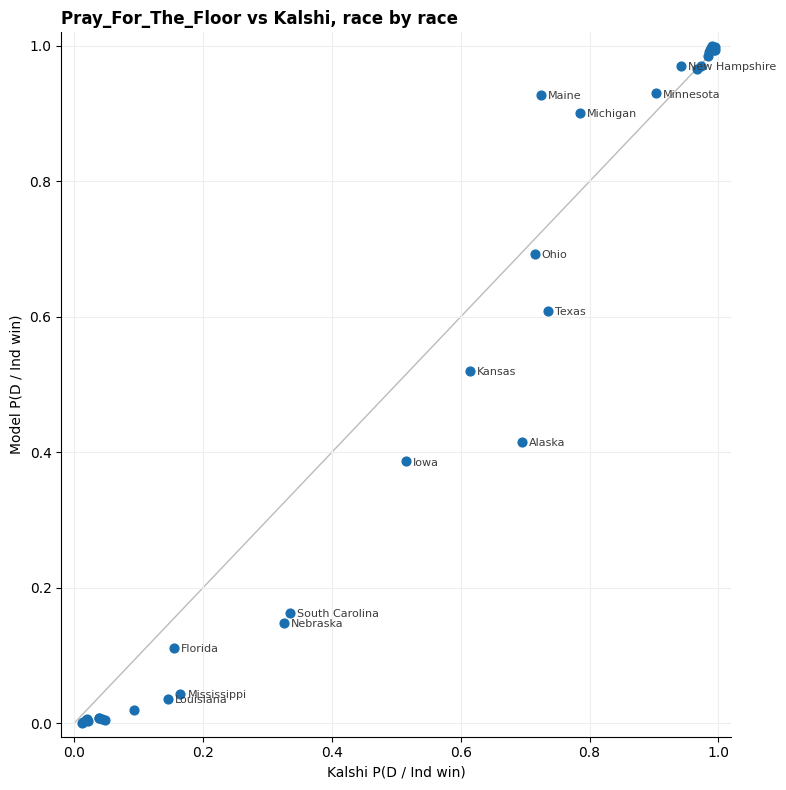

In [21]:
def plot_vs_kalshi(r, path=None):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.plot([0, 1], [0, 1], color="#BBBBBB", lw=1, zorder=1)
    ax.scatter(r["kalshi_p"], r["p_dem"], s=40, color="#1A6FB0", zorder=3)
    for st, row in r.iterrows():
        if 0.1 < row["kalshi_p"] < 0.95 or abs(row["p_dem"] - row["kalshi_p"]) > 0.1:
            ax.annotate(st, (row["kalshi_p"], row["p_dem"]), xytext=(5, -3), textcoords="offset points", fontsize=8, color="#3C3C3C")
    ax.set_xlabel("Kalshi P(D / Ind win)")
    ax.set_ylabel("Model P(D / Ind win)")
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    ax.grid(color="#EEEEEE", zorder=0)
    ax.spines[["right", "top"]].set_visible(False)
    ax.set_title("Pray_For_The_Floor vs Kalshi, race by race", loc="left", fontweight="bold")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


plot_vs_kalshi(RES["races"], CONFIG["OUT_DIR"] / "model_vs_kalshi.png")

### Seat distribution
Blue bars = Democratic control (incl. caucusing independents); red = Republican control. The little triangle marks the average.

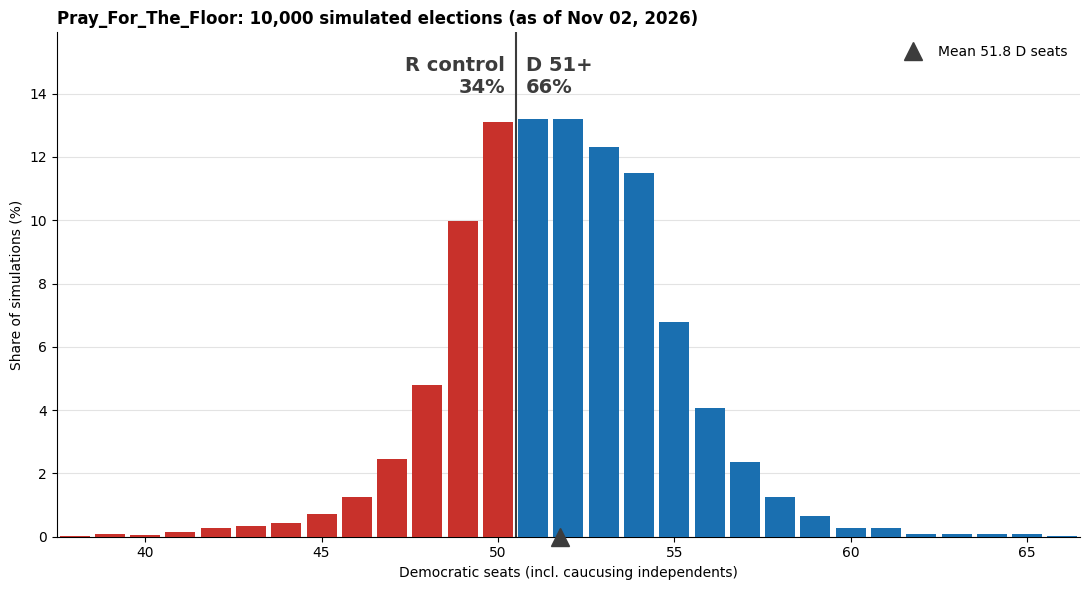

In [22]:
def plot_seat_distribution(d_seats, cfg, today, path=None):
    DEM_BLUE, REP_RED, INK = "#1A6FB0", "#C8312B", "#3C3C3C"
    need = control_threshold(cfg)
    seats, counts = np.unique(d_seats, return_counts=True)
    pct = 100 * counts / len(d_seats)
    p_dem = (d_seats >= need).mean()
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.bar(seats, pct, width=0.85, color=np.where(seats >= need, DEM_BLUE, REP_RED), zorder=3)
    ax.axvline(need - 0.5, color=INK, lw=1.5, zorder=2)
    ax.plot([d_seats.mean()], [0], marker="^", ms=13, color=INK, clip_on=False, zorder=5, ls="none",
            label=f"Mean {d_seats.mean():.1f} D seats")
    top = pct.max() * 1.15
    ax.text(need - 0.8, top, f"R control\n{1 - p_dem:.0%}", ha="right", va="top", color=INK, fontsize=14, fontweight="bold")
    ax.text(need - 0.2, top, f"D {need}+\n{p_dem:.0%}", ha="left", va="top", color=INK, fontsize=14, fontweight="bold")
    ax.set_ylim(0, top * 1.05)
    ax.set_xlim(np.percentile(d_seats, 0.1) - 1.5, np.percentile(d_seats, 99.9) + 1.5)
    ax.set_xlabel("Democratic seats (incl. caucusing independents)")
    ax.set_ylabel("Share of simulations (%)")
    ax.grid(axis="y", color="#E3E3E3", zorder=0)
    ax.spines[["right", "top"]].set_visible(False)
    ax.legend(loc="upper right", frameon=False)
    ax.set_title(f"Pray_For_The_Floor: {len(d_seats):,} simulated elections (as of {today:%b %d, %Y})", loc="left", fontweight="bold")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


plot_seat_distribution(RES["d_seats"], CONFIG, RES["today"], CONFIG["OUT_DIR"] / "seat_distribution.png")

### Save outputs
A JSON snapshot of `CONFIG` and the headline numbers is saved next to the results, so every output leaves a paper trail back to the assumptions that produced it.

In [23]:
out = CONFIG["OUT_DIR"]
_json = lambda x: x.item() if hasattr(x, "item") else str(x)
race_table.to_csv(out / "race_probabilities.csv")
win_table.to_csv(out / "state_win_probabilities.csv")
RES["polls"].to_csv(out / "polls_used.csv", index=False)
RES["env"]["table"].to_csv(out / "national_signals.csv")
pd.Series(RES["d_seats"]).value_counts().sort_index().rename("n_sims").to_csv(out / "seat_distribution.csv", index_label="dem_seats")
with open(out / "config_snapshot.json", "w") as f:
    json.dump({k: v for k, v in CONFIG.items()}, f, indent=2, default=_json)
headline = {"as_of": f"{RES['today']:%Y-%m-%d}", "run_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), **RES["summary"],
            "kalshi_off": RES_NO_KALSHI["summary"], "kalshi_p_control": k_ctrl, "kalshi_expected_seats": k_seats,
            "national": {"generic_ballot": RES["env"]["env_generic"], "net_approval": RES["env"]["net_approval"],
                         "env": RES["env"]["env"], "undecided_share_U": RES["env"]["U"]},
            "sources": SOURCE_STATUS}
with open(out / "headline.json", "w") as f:
    json.dump(headline, f, indent=2, default=_json)
print(f"Saved race_probabilities.csv, state_win_probabilities.csv, polls_used.csv, national_signals.csv, "
      f"seat_distribution.csv/.png, model_vs_kalshi.png, config_snapshot.json, headline.json to {out}")

Saved race_probabilities.csv, state_win_probabilities.csv, polls_used.csv, national_signals.csv, seat_distribution.csv/.png, model_vs_kalshi.png, config_snapshot.json, headline.json to C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast\Senate Forecast\Models\Pray_For_The_Floor\Output


### Standard export for `run_all.py`
Every model in the repo drops the same three files into `Output/standard/`, so `run_all.py` can compare apples to apples without knowing how each orchard grows them: `summary.json` (headline numbers + key settings), `races.csv` (one row per race) and `seats.csv` (seat distribution). See the README at the top of the repo.

In [24]:
STD = CONFIG["OUT_DIR"] / "standard"
STD.mkdir(parents=True, exist_ok=True)
_r = RES["races"]
pd.DataFrame({"state": _r.index, "p_dem": _r["p_dem"].values, "margin": _r["post_mean"].values, "sd": _r["post_sd"].values,
              "kalshi_p": _r["kalshi_p"].values, "n_polls": _r["n_polls"].values}).to_csv(STD / "races.csv", index=False)
_sh = pd.Series(RES["d_seats"]).value_counts(normalize=True).sort_index()
pd.DataFrame({"dem_seats": _sh.index, "share": _sh.values}).to_csv(STD / "seats.csv", index=False)
_c = CONFIG
_ks = f"1/{_c['KALSHI_SD']:g}^2" if kalshi_on(_c) else "0 (comparison only)"
STANDARD = {
    "model": "Pray_For_The_Floor", "variant": "", "run_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
    "as_of": f"{RES['today']:%Y-%m-%d}", **{k: RES["summary"][k] for k in ("p_d_51", "exp_d_seats", "median_d_seats", "p10", "p90")},
    "n_sims": int(_c["N_SIMS"]), "kalshi_p_control": k_ctrl, "kalshi_expected_seats": k_seats, "sources": SOURCE_STATUS,
    "key_settings": {
        "Poll source": "VoteHub API",
        "Poll age": (f"all polls, half-life {_c['RECENCY_HALF_LIFE_DAYS']} days" if _c["RECENCY_MODE"] == "half_life"
                     else f"last {_c['WINDOW_DAYS']} days, weight 1.0 -> {_c['WINDOW_OLDEST_WEIGHT']}"),
        "Polls : fundamentals : Kalshi": (f"Bayesian precision (poll trust x{_c['POLL_PRECISION_MULT']:g}, prior SD {_c['PRIOR_SD']:g}); "
                                          f"Kalshi precision {_ks}"),
        "Poll reliability (thin races)": ("automatic (Bayesian precision)" if _c["POLL_RELIABILITY"] == "bayesian"
                                          else f"Bayesian x n_eff/(n_eff+{_c['POLL_RELIABILITY']})"),
        "Fundamentals": f"PVI x {_c['PVI_TO_MARGIN']:g} + national environment (generic-ballot blend {_c['GENERIC_BALLOT_BLEND']:g})",
        "Incumbency": f"{_c['INCUMBENCY_ADVANTAGE']:g} pts (appointed {_c['APPOINTED_INCUMBENT_ADVANTAGE']:g})",
        "LV : RV : A": " : ".join(f"{v:g}" for v in _c["POPULATION_WEIGHTS"].values()),
        "Flooding penalty": f"1/k^{_c['FLOOD_EXPONENT']}",
        "House effects": ("on (scorecard)" if _c["SCORECARD_HOUSE_EFFECTS"] else "partisan sponsors only")
                         + (" + estimated" if _c["ESTIMATE_HOUSE_EFFECTS"] else ""),
        "Ungraded pollsters": _c["UNRATED_POLLSTERS"] if _c["UNRATED_POLLSTERS"] == "random" else f"rank {_c['UNRANKED_SCORE']} (fixed)",
        "National signals": f"VoteHub polls + Kalshi averages (= {_c['NAT_KALSHI_POLL_EQUIV']} polls)",
        "Kalshi races": "Bayesian input + comparison (found automatically)" if kalshi_on(_c) else "comparison only",
        "Source errors": f"correlated (rho {_c['SOURCE_ERROR_CORR']})" if _c["CORRELATED_ERRORS"] else "independent (Bayesian)",
    },
}
with open(STD / "summary.json", "w") as f:
    json.dump(STANDARD, f, indent=2, default=_json)
print(f"Standard export -> {STD}")

Standard export -> C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast\Senate Forecast\Models\Pray_For_The_Floor\Output\standard


---
**Next:** open **`Model Testing.ipynb`** in this folder. It re-runs this notebook, then pokes and prods the data, flags thin or stale inputs, stress-tests the settings (sensitivity sweep), and charts how the forecast has wandered week by week.